# **Análisis bivariado**

Este análisis retoma exactamente las familias de variables ya descritas univariadamente en la Sección 21 (`inventario`, `GRUPOS_DEMO`, `GRUPOS_NEURO`, `base_full`) y evalúa, variable por variable, su asociación estadística con la **Edad de Inicio (AOO)**. No se incorporan variables nuevas ni se modifica la clasificación analítica ya construida: se prueba únicamente lo que ya fue inventariado y descrito.

**Decisiones metodológicas:**

- **Unidad de análisis:** se usan pares completos por variable (`base_full[[variable, 'aoo']].dropna()`), sin imputar y sin eliminar valores extremos. Esto preserva el mismo principio de la Sección 21 de declarar siempre el denominador efectivo de cada prueba (`n`), que varía de una variable a otra según sus propios faltantes y los de la AOO (85.2% de disponibilidad, preliminar).
- **Pruebas no paramétricas:** se usan pruebas de rangos (Spearman, U de Mann-Whitney, Kruskal-Wallis) en lugar de pruebas paramétricas (Pearson, t, ANOVA), consistente con el uso de correlación de Spearman ya adoptado en la Sección 20 y con la naturaleza no necesariamente normal de la AOO y de varias covariables ordinales/discretas.
- **Corrección por comparaciones múltiples:** dado el número de pruebas realizadas, todos los p-valores se corrigen conjuntamente por FDR (Benjamini-Hochberg) en la Sección 22.15, evitando interpretar como "hallazgo" cualquier p<0.05 aislado.
- **Riesgo de leakage como filtro de interpretación, no de exclusión:** todas las variables se prueban, incluidas las de riesgo "Alto" o "Potencial" (p. ej. MMSE, MoCA, FAST, comorbilidades sin temporalidad confirmada). Una asociación estadísticamente significativa en esas variables **no se interpreta como factor de riesgo** para una AOO más temprana o tardía, sino como covariación entre el estado clínico actual y la AOO. La columna `riesgo_leakage_aoo` del inventario acompaña cada resultado para que esta distinción sea explícita en todo momento.
- **No se prueban:** identificadores, variables auxiliares del EDA (`edad de inicio`/`edad de inicio actualizada`, que son insumos de la propia AOO), variables de texto libre/alta cardinalidad, variables constantes, y variables cuyo `n` efectivo o cuyo tamaño de grupo sea insuficiente. Estas exclusiones se documentan explícitamente por variable en la tabla de resultados (columna `motivo`) y se resumen en la Sección 22.16.
- **Las celdas «Hallazgos principales» se dejan en blanco intencionalmente**, igual que en la Sección 21: deben completarse tras ejecutar el notebook con los archivos fuente, inspeccionando las tablas y gráficos generados.

## **1. Configuración inicial y carga de datos**

In [1]:
import math
import pickle
import re
import textwrap
import unicodedata
from pathlib import Path
# 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown

pd.set_option("display.max_columns", 200)
pd.set_option("display.max_rows", 300)
pd.set_option("display.max_colwidth", 120)

plt.rcParams.update({
    "figure.figsize": (7, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.3,
    "font.size": 10,
})

SALIDAS = Path("salidas")
CODIGO_NO_REGISTRADO="-"
ETIQUETA_NO_REGISTRADO="No registrado"

base_full = pd.read_pickle(SALIDAS / "base_full.pkl")
inventario = (pd.read_pickle(SALIDAS / "inventario.pkl"))

with open(SALIDAS / "objetos_preprocesamiento.pkl", "rb") as f:
    obj = pickle.load(f)
neuro_norm = obj["neuro_norm"]

<br>

## **2. Criterios metodológicos y funciones auxiliares del bivariado**

La prueba usada por variable depende de `tipo_analitico` (ya definido en el inventario de la Sección Univariado):

- `cuantitativa continua` / `cuantitativa discreta`: correlación de Spearman con AOO.
- `ordinal`: se intenta primero como numérica (si ≥80% de los valores no faltantes son convertibles a número, se asume que la codificación ordinal ya es numérica y se usa Spearman); si no, se trata como categórica sin orden validado (se documenta explícitamente) y se compara por grupos.
- `categórica binaria` (2 categorías con n suficiente): U de Mann-Whitney, con r biserial por rangos como medida de efecto.
- `categórica nominal` (≥3 categorías con n suficiente): Kruskal-Wallis, con épsilon al cuadrado como medida de efecto.
- `identificador`, `variable auxiliar del EDA`, `texto libre / alta cardinalidad`: no se prueban formalmente.

Las categorías con menos de `n_min_grupo` pacientes se excluyen de la prueba de grupos (no del inventario ni de la cohorte) y quedan fuera del cálculo de `k`; esto se documenta si reduce el número de grupos comparados.


In [2]:
from funciones.funciones_bivariado import *

pruebas_bivariadas_globales=[]
print("Funciones bivariadas listas.")  

Funciones bivariadas listas.


<br>

## **3. AOO y variables sociodemográficas**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación.

**Edad frente a AOO requiere una lectura especial.** Ambas variables están temporal y matemáticamente vinculadas: la edad de inicio no puede superar la edad actual y la duración de enfermedad conecta ambas medidas. Por ello, una correlación alta es esperable y no convierte la edad actual en una covariable independiente atractiva para modelar AOO sin considerar duración y temporalidad.

Las variables categóricas con códigos sin diccionario se marcan como **«Resultado estadístico preliminar sujeto a validación de codificación»**. Sus pruebas pueden calcularse, pero no se interpretan sustantivamente hasta confirmar las categorías y los códigos especiales (`9`, `-`, desconocido/no aplica).


Variables integradas en la familia: **11**

**Pruebas de asociación con AOO — Variables sociodemográficas**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
genero,categórica binaria,Bajo,Sí,U de Mann-Whitney,334,11192.00,0.092,r biserial por rangos,Comparar medianas de AOO entre grupos,Femenino: 75.0 Masculino: 77.0,Sí,—,0.1736,—,—
mes y año de nacimiento,texto libre / alta cardinalidad,Bajo / revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
EDAD,cuantitativa continua,Bajo / revisar temporalidad,Sí,Spearman,334,0.84,0.840,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.0000,—,—
IDIOMA,categórica nominal,Bajo,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
OTRO IDOMA,texto libre / alta cardinalidad,Bajo,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
Nivel educativo,ordinal,Bajo,Sí,Spearman,324,-0.18,-0.176,rho de Spearman,Valores mayores asociados con AOO menor,—,Sí,—,0.0014,—,—
Estado civil,categórica nominal,Bajo / revisar temporalidad,Sí,Kruskal-Wallis (k=4),311,15.78,0.042,épsilon cuadrado,Comparar medianas de AOO entre grupos,Casado: 74.0 Separado: 75.0 Soltero (nunca casado o matrimonio anulado): 74.0 Viudo: 79.0,Sí,—,0.0013,—,—
Estado Habitacional,categórica nominal,Bajo / revisar temporalidad,Sí,Kruskal-Wallis (k=6),327,19.20,0.044,épsilon cuadrado,Comparar medianas de AOO entre grupos,"Vive con otra persona: esposo o pareja: 75.0 Vive con otra persona: familiar, amigo o compañero de cuarto: 78.0 Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo: 71.0 Vive con un grupo de personas (familiares o no) en una residencia privada: 74.0 Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos): 80.0 Vive solo: 72.0",Sí,—,0.0018,—,—
Nivel de independencia,ordinal,Bajo / revisar temporalidad,Sí,Spearman,332,0.12,0.121,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.0278,—,—
Tipo de residencia,categórica nominal,Bajo / revisar temporalidad,Sí,U de Mann-Whitney,332,7067.50,-0.326,r biserial por rangos,Comparar medianas de AOO entre grupos,"Hospital, hospicio, asilo de ancianos, residencia de cuidados médicos especializados: 80.0 Residencia privada (departamento, condominio, casa): 75.0",Sí,—,0.0014,—,—


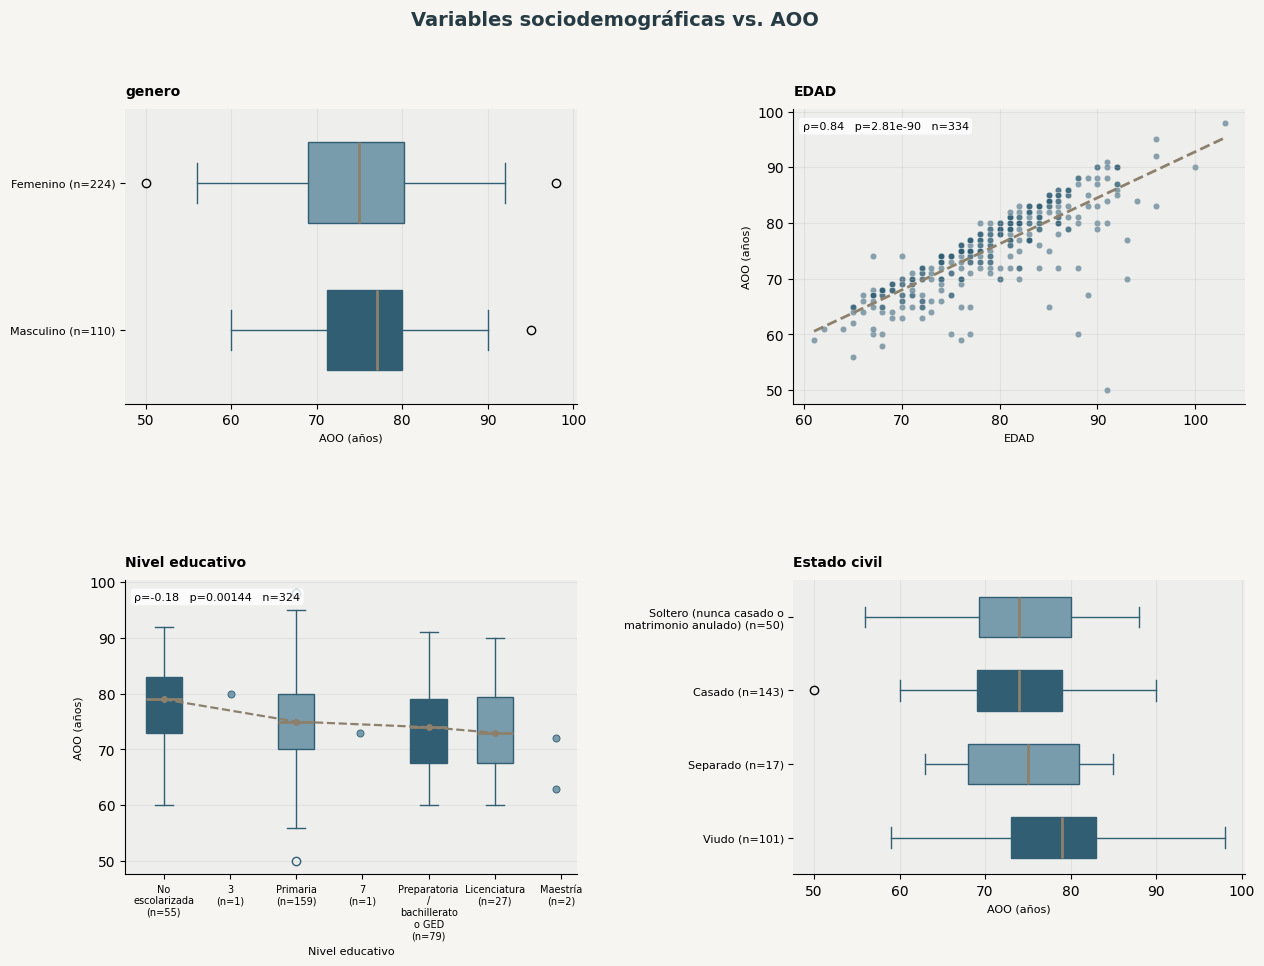

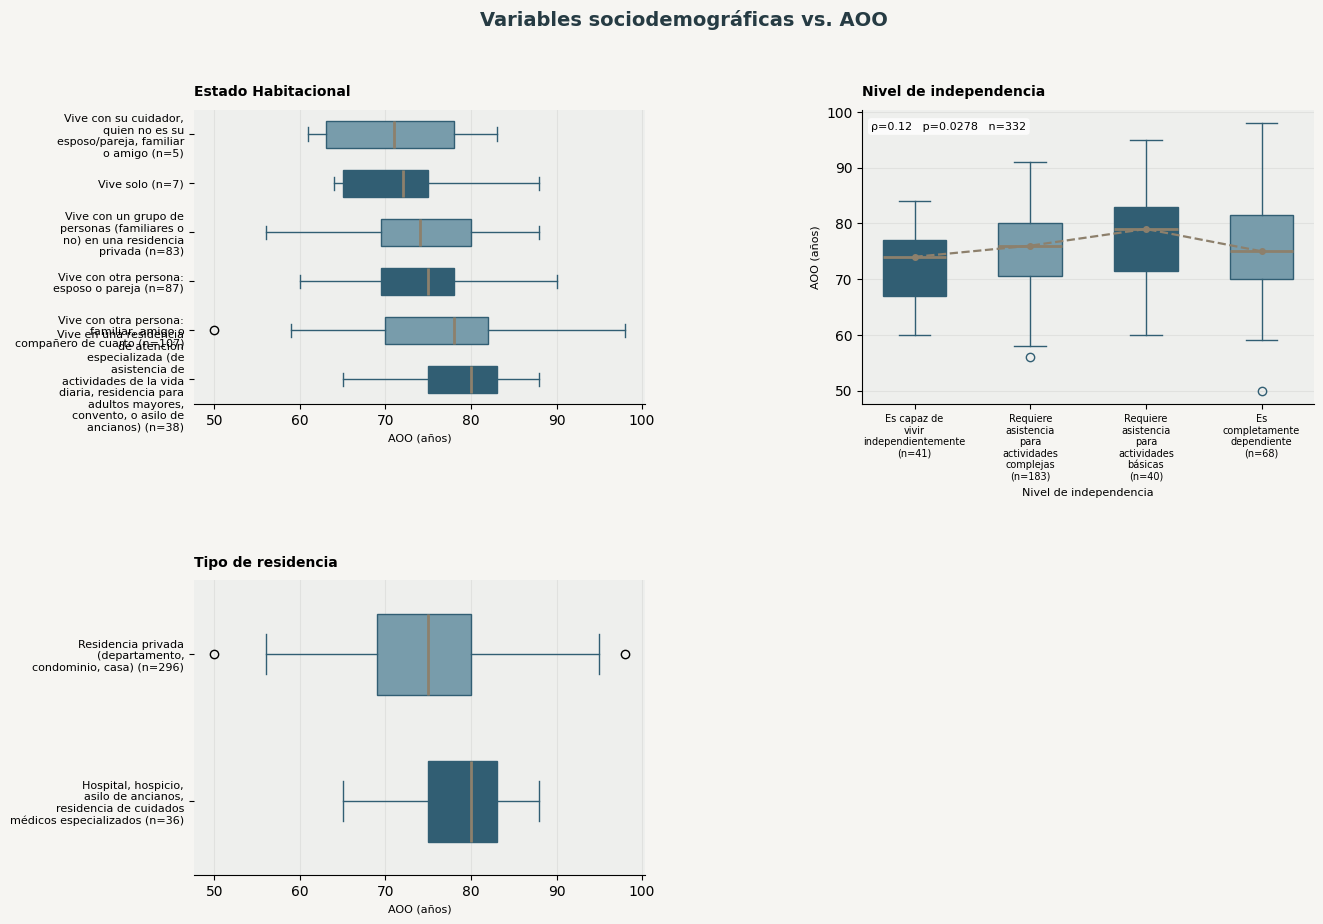

In [3]:
columnas = inventario.loc[(inventario.familia == 'sociodemograficas') &
    ~inventario.tipo_analitico.isin(['identificador', 'variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))
tabla_biv_sociodem = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Variables sociodemográficas',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [4]:
mostrar_hallazgos_bivariados(tabla_biv_sociodem, 'variables sociodemográficas')


Se analizaron 7 variables del grupo «sociodemográficas». 6 variables mostraron una señal estadística antes de corregir por las múltiples comparaciones. EDAD presentó una tendencia marcada: sus valores más altos coincidieron con una AOO mayor; su utilidad como covariable exige confirmar la temporalidad. Estado civil mostró diferencias de AOO entre sus categorías (Casado: 74.0 años; Separado: 75.0 años; Soltero (nunca casado o matrimonio anulado): 74.0 años; Viudo: 79.0 años); su utilidad como covariable exige confirmar la temporalidad. Tipo de residencia mostró diferencias de AOO entre sus categorías (Hospital, hospicio, asilo de ancianos, residencia de cuidados médicos especializados: 80.0 años; Residencia privada (departamento, condominio, casa): 75.0 años); su utilidad como covariable exige confirmar la temporalidad. Nivel educativo presentó una tendencia débil: sus valores más altos coincidieron con una AOO menor. 2 señales preliminares adicionales se detallan en la tabla. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. No pudieron evaluarse formalmente 4 variables, entre ellas mes y año de nacimiento, IDIOMA, OTRO IDOMA.

<br>

## **4. AOO e informante y red de apoyo**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.


Variables integradas en la familia: **5**

**Pruebas de asociación con AOO — Informante y red de apoyo**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
Relación del Informante,categórica nominal,Revisar temporalidad,Sí,Kruskal-Wallis (k=6),334,14.57,0.029,épsilon cuadrado,Comparar medianas de AOO entre grupos,"Amigo, vecino o conocido de la familia/amigos/ trabajo o de la comunidad (por ejemplo, de la iglesia).: 80.0 Esposo(a), pareja, compañero (incluyendo exesposo(a), ex-pareja, prometido(a), novio(a)): 74.5 Hermano (consanguíneo, hermanastro, adoptado): 69.5 Hijo (consanguíneo, hijastro, adoptado): 77.0 Otro familiar (consanguíneo, adquirido por el matrimonio, adoptado): 75.0 Paciente: 75.0",Sí,—,0.0124,—,—
Tiempo (años de conocerce),cuantitativa continua,Revisar temporalidad,Sí,Spearman,134,0.15,0.151,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.0822,—,—
¿Vive el informante con el sujeto?,categórica nominal,Revisar temporalidad,Sí,U de Mann-Whitney,282,5589.50,0.105,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 74.0 Sí: 75.0,Sí,—,0.2287,—,—
"Si el informante no vive con el sujeto, ¿con qué frecuencia visita personalmente al sujeto?",ordinal,Revisar temporalidad,Sí,Spearman,226,-0.10,-0.103,rho de Spearman,Valores mayores asociados con AOO menor,—,Sí,—,0.1237,—,—
"Si el informante no vive con el sujeto, ¿con qué frecuencia tiene contacto telefónico con él?",ordinal,Revisar temporalidad,Sí,Spearman,226,-0.10,-0.101,rho de Spearman,Valores mayores asociados con AOO menor,—,Sí,—,0.1298,—,—


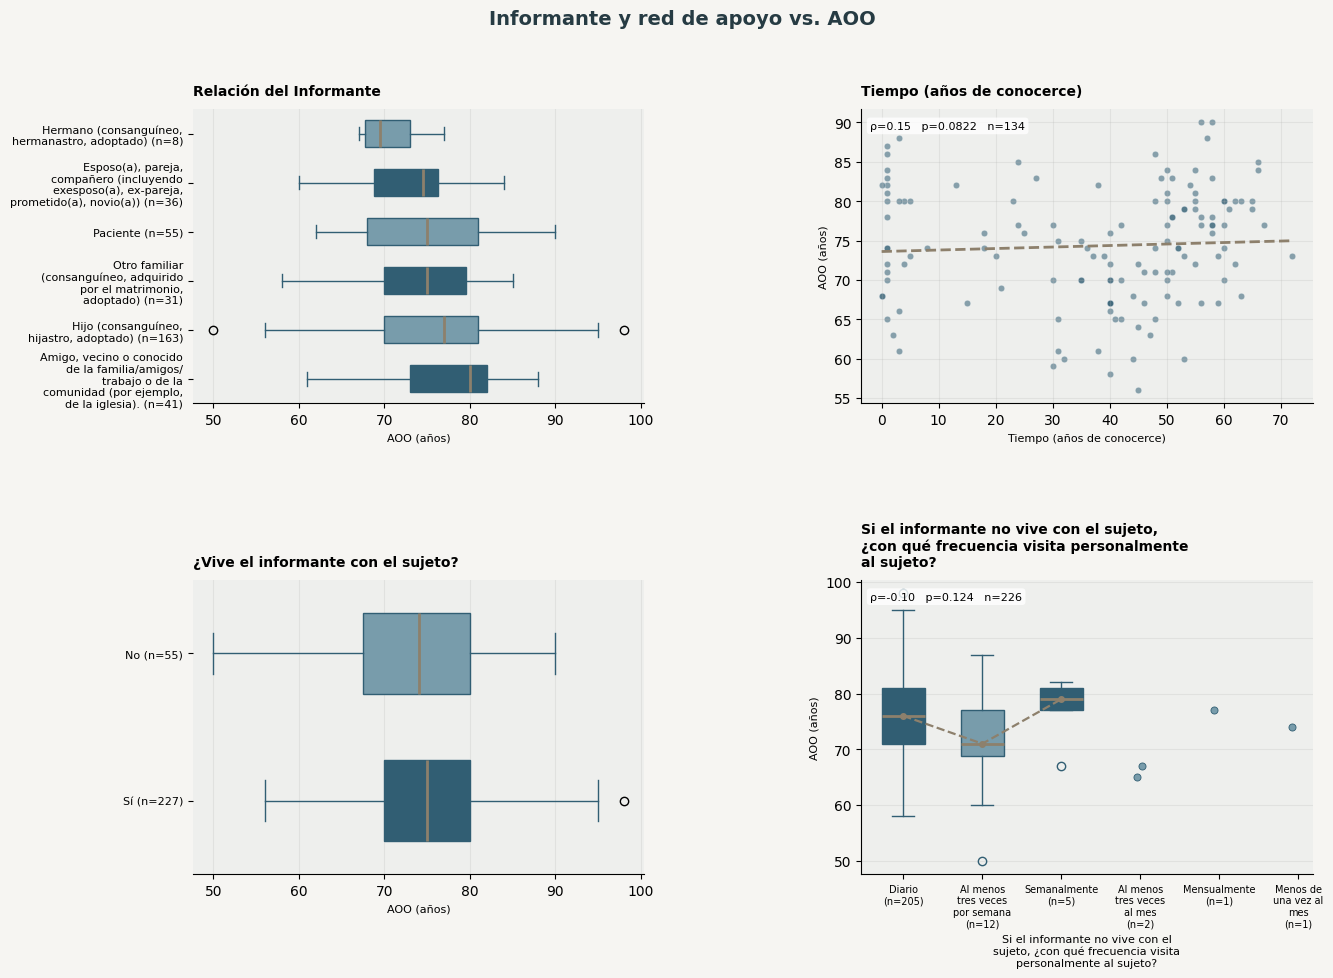

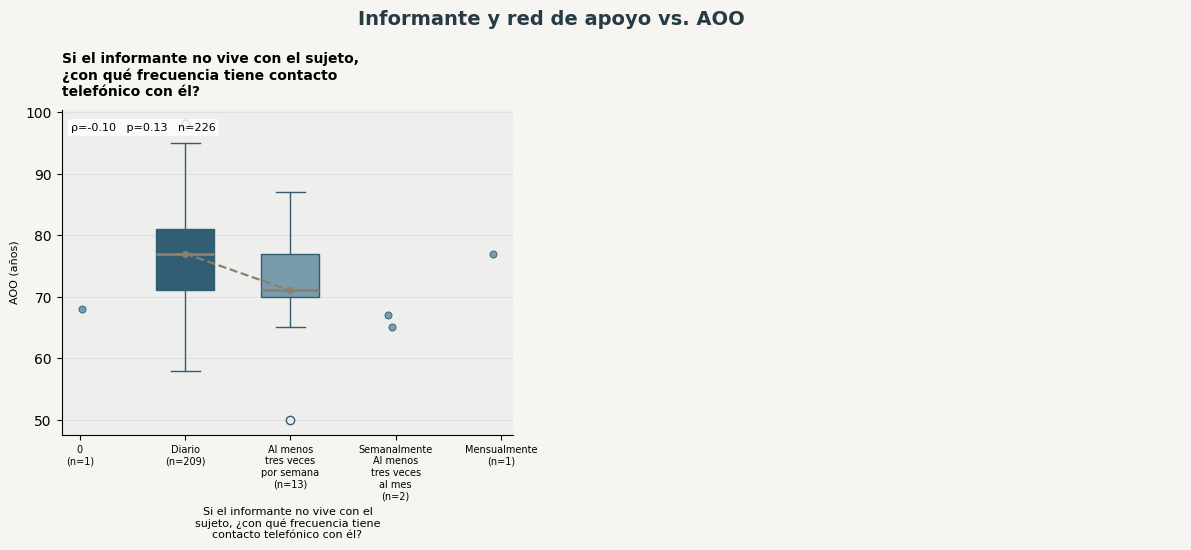

In [5]:
columnas = inventario.loc[(inventario.familia == 'informante_red_apoyo') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_informante = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Informante y red de apoyo',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [6]:
mostrar_hallazgos_bivariados(tabla_biv_informante, 'informante y red de apoyo')


Se analizaron 5 variables del grupo «informante y red de apoyo». 1 variable mostró una señal estadística antes de corregir por las múltiples comparaciones. Relación del Informante mostró diferencias de AOO entre sus categorías (Amigo, vecino o conocido de la familia/amigos/ trabajo o de la comunidad (por ejemplo, de la iglesia): 80.0 años; Esposo(a), pareja, compañero (incluyendo exesposo(a), ex-pareja, prometido(a), novio(a)): 74.5 años; Hermano (consanguíneo, hermanastro, adoptado): 69.5 años; Hijo (consanguíneo, hijastro, adoptado): 77.0 años; Otro familiar (consanguíneo, adquirido por el matrimonio, adoptado): 75.0 años; y 1 grupo adicional); su utilidad como covariable exige confirmar la temporalidad. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. 

<br>

## **5. AOO e historia familiar**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.


Variables integradas en la familia: **2**

**Pruebas de asociación con AOO — Historia familiar**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
"¿Hay miembros afectados de la familia (padres biológicos, hermanos consanguíneos completos (comparten ambos padres), o hijos biológicos)?",categórica nominal,Bajo / revisar temporalidad,Sí,U de Mann-Whitney,320,13812.50,-0.124,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 76.0 Sí: 75.0,Sí,—,0.0599,—,—
Familiar afectado,categórica nominal,Bajo,Sí,Kruskal-Wallis (k=6),171,4.02,-0.006,épsilon cuadrado,Comparar medianas de AOO entre grupos,Abuelos: 74.0 Código 0 (sin etiqueta documentada): 74.0 Dos: 72.0 Hermanos: 76.0 Padres: 72.5 Tios: 75.0,Sí,—,0.5471,—,—


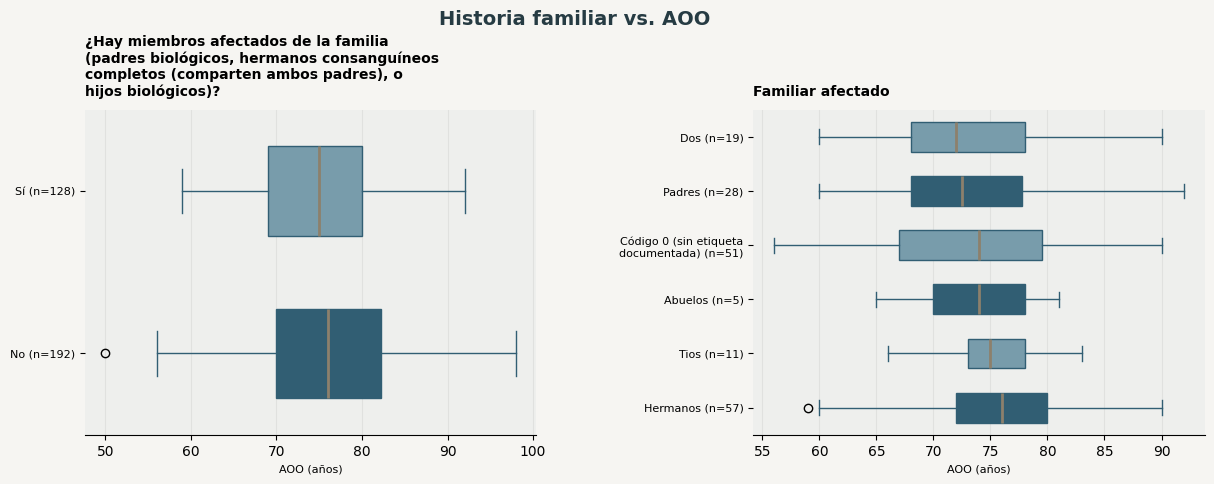

In [7]:
columnas = inventario.loc[(inventario.familia == 'historia_familiar') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_historia_familiar = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Historia familiar',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [8]:
mostrar_hallazgos_bivariados(tabla_biv_historia_familiar, 'historia familiar')


Se analizaron 2 variables del grupo «historia familiar». Ninguna mostró señal con p<0.05 antes de corregir por comparaciones múltiples.

<br>

## **6. AOO y antropometría**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

Variables integradas en la familia: **2**

**Pruebas de asociación con AOO — Antropometría**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
Peso,cuantitativa continua,Revisar temporalidad,Sí,Spearman,260,0.03,0.028,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.6514,—,—
Talla,cuantitativa continua,Revisar temporalidad,Sí,Spearman,299,0.09,0.089,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.1259,—,—


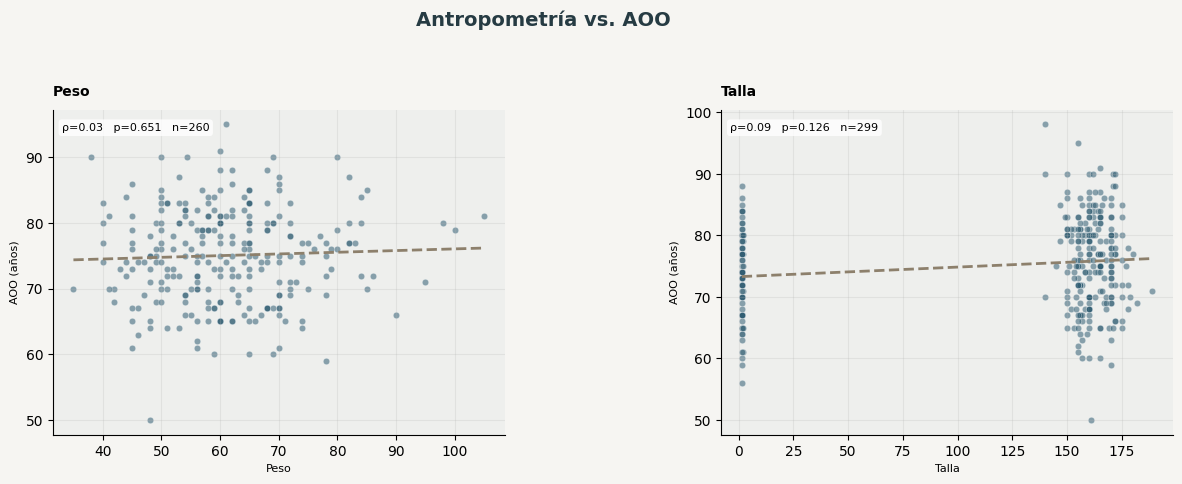

In [9]:
columnas = inventario.loc[(inventario.familia == 'antropometria') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_antropometria = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Antropometría',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [10]:
mostrar_hallazgos_bivariados(tabla_biv_antropometria, 'antropometría')


Se analizaron 2 variables del grupo «antropometría». Ninguna mostró señal con p<0.05 antes de corregir por comparaciones múltiples.

<br>

## **7. AOO y medicamentos**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

In [11]:
columnas = inventario.loc[(inventario.familia == 'medicamentos') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_medicamentos = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Medicamentos',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

Variables integradas en la familia: **9**

**Pruebas de asociación con AOO — Medicamentos**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
MEDICAMENTO DEL SUJETO 1,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 2,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 3,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 4,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 5,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 6,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 7,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 8,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
MEDICAMENTO DEL SUJETO 9,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—


#### **Hallazgos principales**


In [12]:
mostrar_hallazgos_bivariados(tabla_biv_medicamentos, 'medicamentos')


En el grupo «medicamentos» ninguna variable reunió condiciones mínimas para comparación formal con AOO.

<br>

## **8. AOO y tabaquismo/hábitos**

Se usa `serie_univariada`, que ya recodifica el código 99 de años de tabaquismo como faltante para esta vista, sin alterar la columna original.

Variables integradas en la familia: **3**

**Pruebas de asociación con AOO — Tabaquismo y hábitos**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
El sujeto ha fumado en los pasados 30 días,categórica nominal,Revisar temporalidad,No,—,327,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
¿El sujeto ha fumado más de 100 cigarros / cigarrillos en su vida?,categórica nominal,Revisar temporalidad,Sí,U de Mann-Whitney,326,9002.50,0.069,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 77.0,Sí,—,0.3564,—,—
Número total de años que ha fumado el sujeto (99 = desconocido):,cuantitativa continua,Revisar temporalidad,Sí,Spearman,296,0.07,0.073,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.2099,—,—


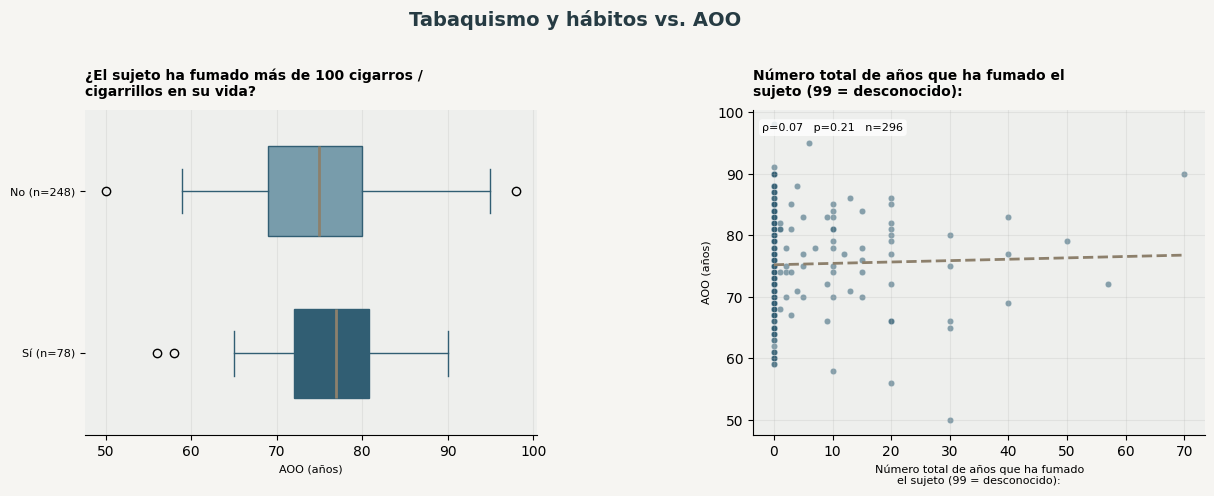

In [13]:
columnas = inventario.loc[(inventario.familia == 'tabaquismo') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_tabaquismo = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Tabaquismo y hábitos',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [14]:
mostrar_hallazgos_bivariados(tabla_biv_tabaquismo, 'tabaquismo y hábitos')


Se analizaron 2 variables del grupo «tabaquismo y hábitos». Ninguna mostró señal con p<0.05 antes de corregir por comparaciones múltiples.No pudo evaluarse formalmente 1 variable: El sujeto ha fumado en los pasados 30 días.

<br>

## **9. AOO y antecedentes cardiovasculares/cerebrovasculares**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

Variables integradas en la familia: **7**

**Pruebas de asociación con AOO — Antecedentes cardiovasculares y cerebrovasculares**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
Ataque cardiaco o paro cardíaco,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,333,1228.00,-0.252,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 69.0,Sí,—,0.2910,—,—
Fibrilación auricular,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,333,449.50,0.542,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 80.5,Sí,—,0.0229,—,—
Angioplastía/ endarterectomía/ stent,categórica nominal,Revisar temporalidad,No,—,334,—,—,—,—,—,No,Codificación pendiente de validación,—,Menos de 2 categorías con n≥5,—
Bypass cardíaco/coronario,categórica binaria,Revisar temporalidad,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Marcapasos y/o desfibrilador,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,334,639.50,0.222,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 80.0,Sí,—,0.3940,—,—
Insuficiencia cardíaca congestiva,categórica binaria,Revisar temporalidad,No,—,330,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
ENFERMEDAD CEREBRO-VASCULAR (ECV),categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,333,1357.50,0.069,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 75.0,Sí,—,0.7253,—,—


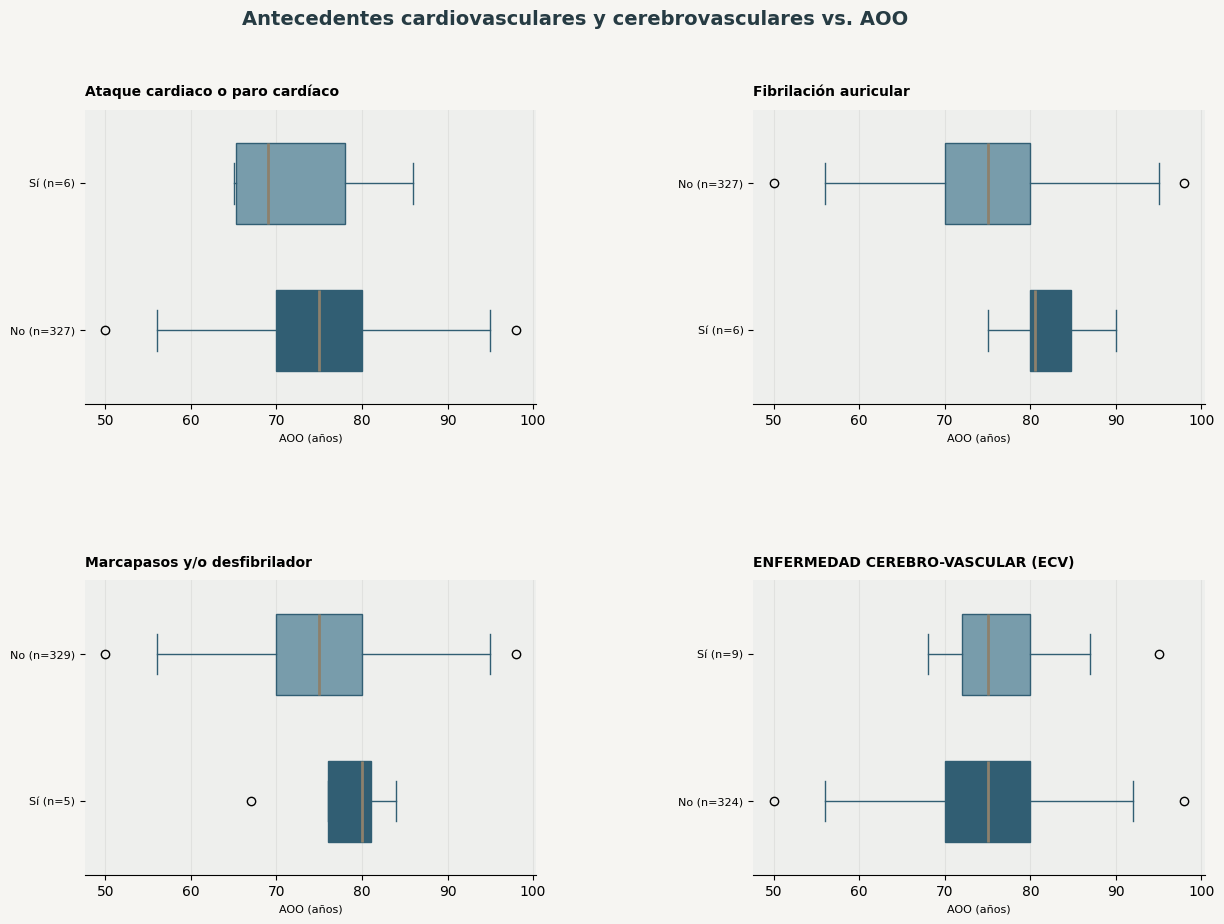

In [15]:
columnas = inventario.loc[(inventario.familia == 'cardiovasculares_cerebrovasculares') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_tabaquismo = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Antecedentes cardiovasculares y cerebrovasculares',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [16]:
mostrar_hallazgos_bivariados(tabla_biv_tabaquismo, 'tabaquismo y hábitos')


Se analizaron 4 variables del grupo «tabaquismo y hábitos». 1 variable mostró una señal estadística antes de corregir por las múltiples comparaciones. Fibrilación auricular mostró diferencias de AOO entre sus categorías (No: 75.0 años; Sí: 80.5 años); su utilidad como covariable exige confirmar la temporalidad. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. No pudieron evaluarse formalmente 3 variables, entre ellas Angioplastía/ endarterectomía/ stent, Bypass cardíaco/coronario, Insuficiencia cardíaca congestiva.

<br>

## **10. AOO y antecedentes neurológicos**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

In [17]:
columnas = inventario.loc[(inventario.familia == 'neurologicos') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_neurologicos = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Antecedentes neurológicos',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

Variables integradas en la familia: **3**

**Pruebas de asociación con AOO — Antecedentes neurológicos**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
PARKINSON,categórica binaria,Revisar temporalidad,No,—,331,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
CONVULSIONES,categórica binaria,Revisar temporalidad,No,—,330,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
TRAUMATISMO DE CRÁNEO-ENCEFÁLICO (TCE),categórica binaria,Revisar temporalidad,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—


Los antecedentes neurológicos no pudieron someterse a comparación formal con AOO debido a la baja frecuencia de casos positivos. Parkinson presentó menos de 5 pacientes en la categoría positiva, al igual que convulsiones, mientras que TCE no presentó variabilidad suficiente. Por tanto, estas variables se conservan para caracterización descriptiva, pero no se realiza inferencia bivariada.

#### **Hallazgos principales**


In [18]:
mostrar_hallazgos_bivariados(tabla_biv_neurologicos, 'antecedentes neurológicos')

En el grupo «antecedentes neurológicos» ninguna variable reunió condiciones mínimas para comparación formal con AOO.

<br>

## **11. AOO y comorbilidades/condiciones médicas**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

Variables integradas en la familia: **13**

**Pruebas de asociación con AOO — Comorbilidades y condiciones médicas**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
DIABETES,categórica nominal,Revisar temporalidad,Sí,Kruskal-Wallis (k=3),332,1.46,-0.002,épsilon cuadrado,Comparar medianas de AOO entre grupos,No: 75.0 Tipo 1: 77.0 Tipo 2: 76.0,Sí,—,0.4818,—,—
CANCER,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,332,617.00,0.245,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 79.0,Sí,—,0.3473,—,—
Hipercholesterolemia,categórica binaria,Revisar temporalidad,No,—,329,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Hipertensión arterial,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,333,10615.00,0.221,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 73.0 Sí: 77.0,Sí,—,0.0005,—,—
NIVELES DE VITAMINA D,categórica nominal,Revisar temporalidad,No,—,334,—,—,—,—,—,No,Codificación pendiente de validación,—,Menos de 2 categorías con n≥5,—
Deficiencia de B12,categórica binaria,Revisar temporalidad,No,—,333,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Enfermedad tiroidea,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,334,2795.00,0.066,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 78.0,Sí,—,0.6295,—,—
Artritis,categórica binaria,Revisar temporalidad,No,—,333,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Artrosis,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,334,3326.50,0.031,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 76.5,Sí,—,0.8103,—,—
Osteoporosis,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,334,1407.00,0.038,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 78.0,Sí,—,0.8472,—,—


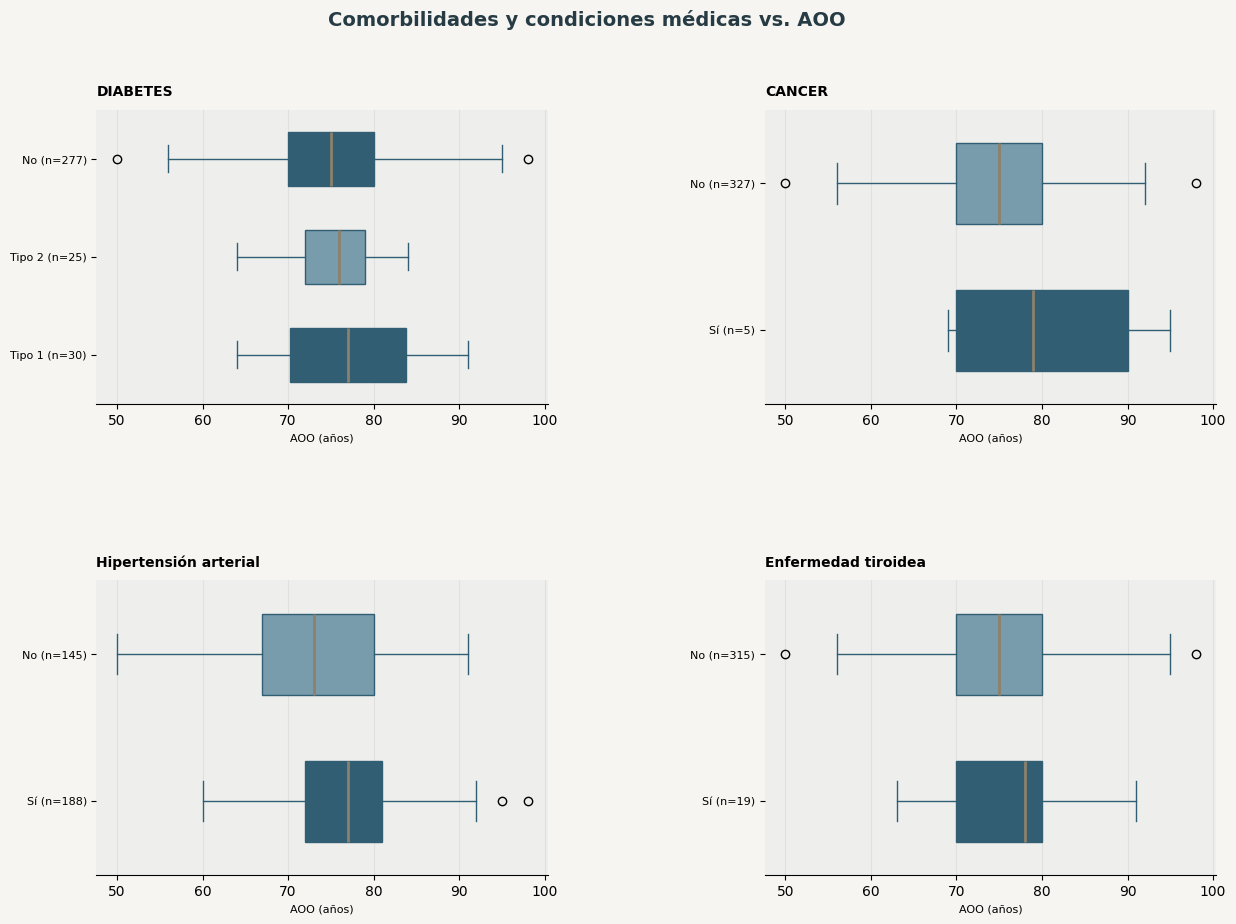

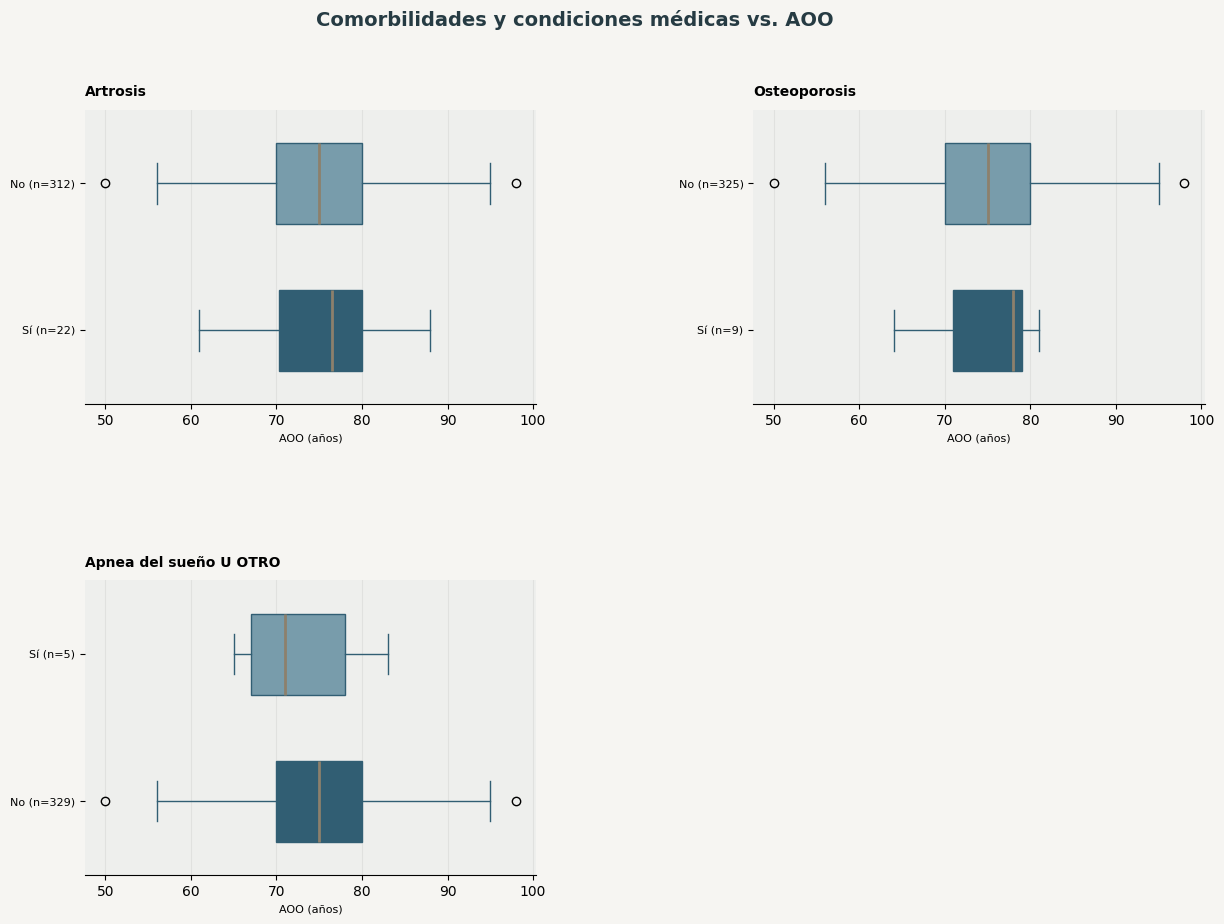

In [19]:
columnas = inventario.loc[(inventario.familia == 'metabolicos_otros') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_comorbilidades = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Comorbilidades y condiciones médicas',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [20]:
mostrar_hallazgos_bivariados(tabla_biv_comorbilidades, 'comorbilidades y condiciones médicas')

Se analizaron 7 variables del grupo «comorbilidades y condiciones médicas». 1 variable mostró una señal estadística antes de corregir por las múltiples comparaciones. Hipertensión arterial mostró diferencias de AOO entre sus categorías (No: 73.0 años; Sí: 77.0 años); su utilidad como covariable exige confirmar la temporalidad. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. No pudieron evaluarse formalmente 6 variables, entre ellas Hipercholesterolemia, NIVELES DE VITAMINA D, Deficiencia de B12.

<br>

## **12. AOO y antecedentes psiquiátricos**

Se evalúa si estas variables muestran asociación estadística con la AOO. Una asociación significativa no implica antecedencia temporal confirmada; la columna `riesgo_leakage_aoo` orienta la interpretación de cada resultado.

Variables integradas en la familia: **7**

**Pruebas de asociación con AOO — Antecedentes psiquiátricos**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
Trastorno de estrés postraumático (TEPT),categórica binaria,Revisar temporalidad,No,—,333,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Trastorno bipolar,categórica binaria,Revisar temporalidad,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Esquizofrenia,categórica binaria,Revisar temporalidad,No,—,331,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Depresión,categórica binaria,Revisar temporalidad,Sí,U de Mann-Whitney,333,1225.00,-0.249,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 75.0 Sí: 71.0,Sí,—,0.2969,—,—
Ansiedad,categórica binaria,Revisar temporalidad,No,—,330,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
Trastorno obsesivo-compulsivo (TOC),categórica binaria,Revisar temporalidad,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—
"Trastornos neuropsiquiátricos del desarrollo (por ejemplo, trastorno del espectro autista (TEA), déficit de atención con hiperactividad (TDAH), dislexia)",categórica binaria,Revisar temporalidad,No,—,334,—,—,—,—,—,Sí,—,—,Menos de 2 categorías con n≥5,—


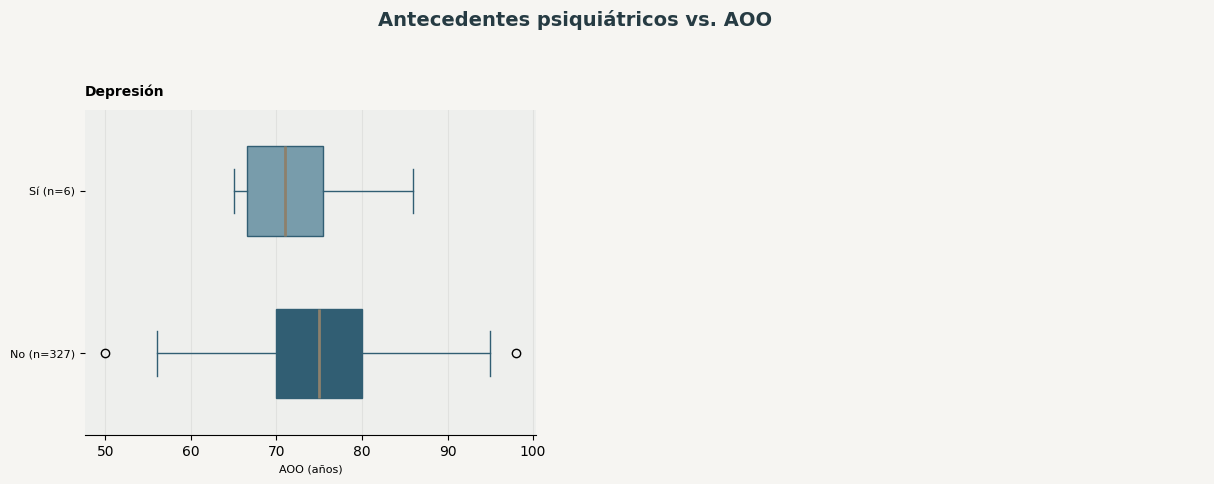

In [21]:
columnas = inventario.loc[(inventario.familia == 'psiquiatricos') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_psiquiatricos = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Antecedentes psiquiátricos',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [22]:
mostrar_hallazgos_bivariados(tabla_biv_psiquiatricos, 'antecedentes psiquiátricos')

Se analizaron 1 variable del grupo «antecedentes psiquiátricos». Ninguna mostró señal con p<0.05 antes de corregir por comparaciones múltiples.No pudieron evaluarse formalmente 6 variables, entre ellas Trastorno de estrés postraumático (TEPT), Trastorno bipolar, Esquizofrenia.

<br>

## **13. AOO y variables clínicas HXGEN**

Estas variables provienen de la cohorte maestra (`hxgen`); su relación con la temporalidad respecto al inicio de la enfermedad aún no está confirmada (riesgo de leakage «Revisar temporalidad» en la mayoría de los casos).

Variables integradas en la familia: **23**

**Pruebas de asociación con AOO — Variables clínicas HXGEN**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
Edad,cuantitativa continua,Revisar temporalidad,Sí,Spearman,333,0.82,0.824,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.0000,—,—
Ciudad o municipio de residencia,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
Enfermedad actual,texto libre / alta cardinalidad,Alto,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
¿Qué síntomas presenta?,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
El Paciente necesita apoyo para realizar las siguientes tareas,texto libre / alta cardinalidad,Alto,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
Indique que estudios previos le han realizado.,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
"Si le han realizado estudios previos, ¿Encontraron hallazgos? ¿Cuales?",texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
Antecedentes,texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—
¿Actualmente se encuentra en algún tratamiento farmacológico?,categórica nominal,Revisar temporalidad,Sí,U de Mann-Whitney,333,6340.00,0.118,r biserial por rangos,Comparar medianas de AOO entre grupos,No: 74.0 Sí: 76.0,No,Codificación pendiente de validación,0.1784,—,Codificación pendiente de validación
"Si la respuesta anterior fue SI, ¿Qué medicamentos está consumiendo?",texto libre / alta cardinalidad,Revisar temporalidad,No,—,—,—,—,—,—,—,Sí,—,—,Tipo no apto para prueba formal,—


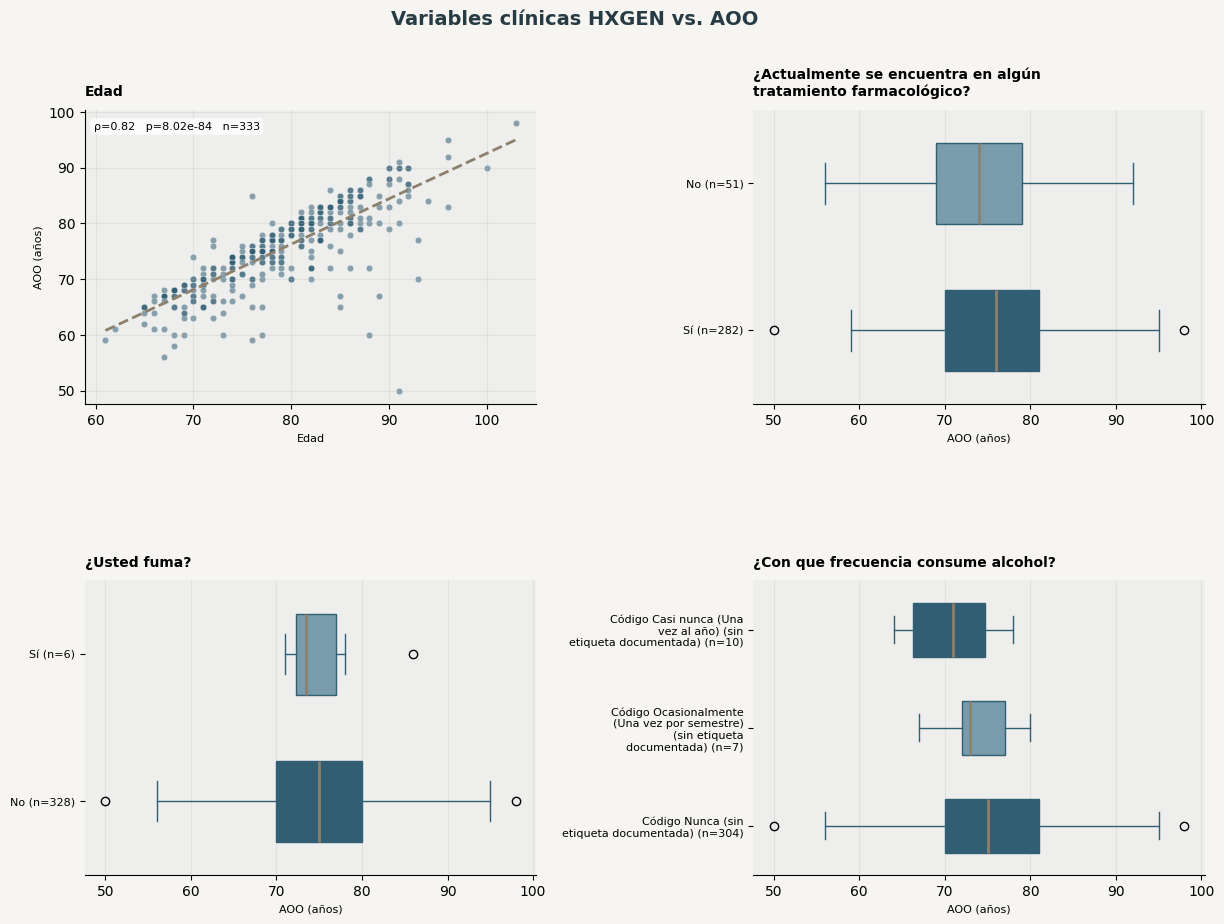

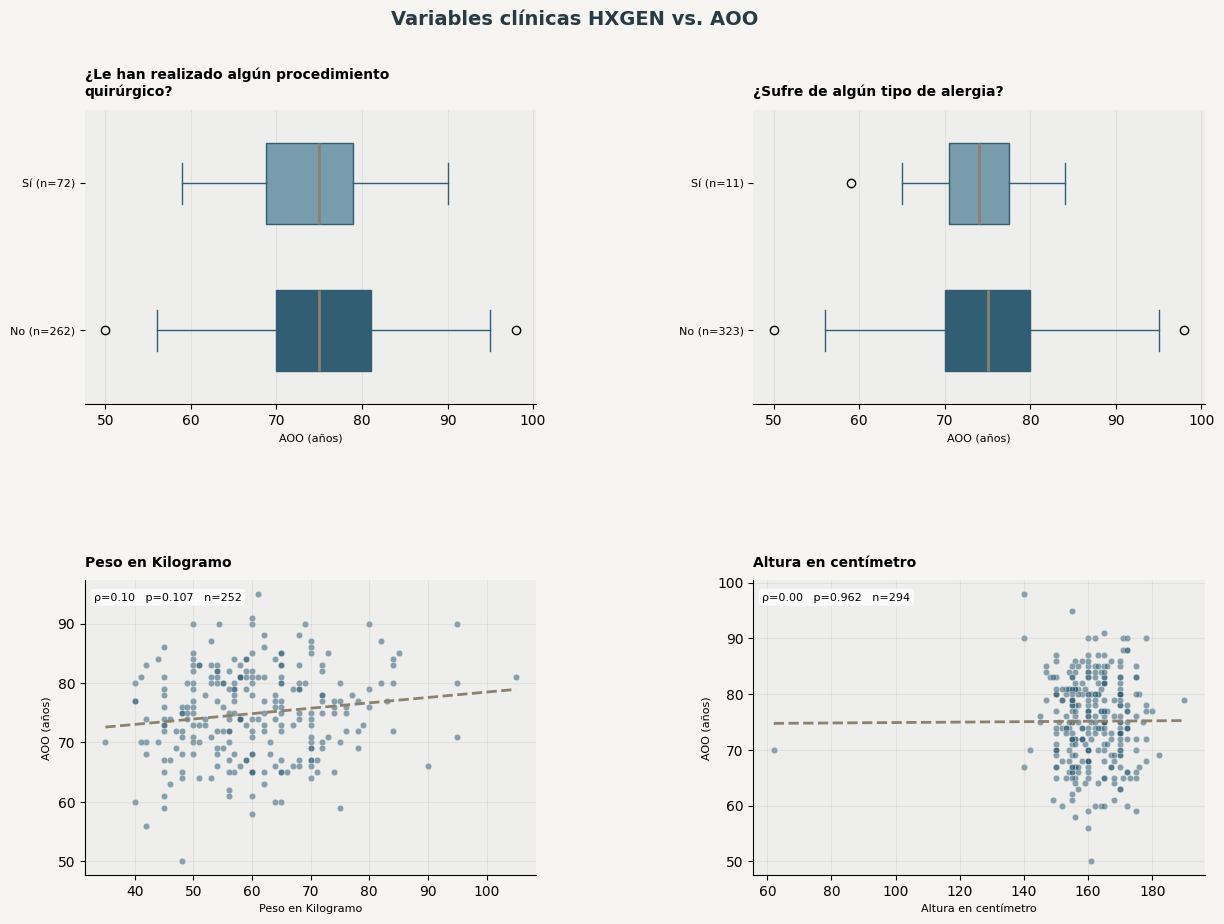

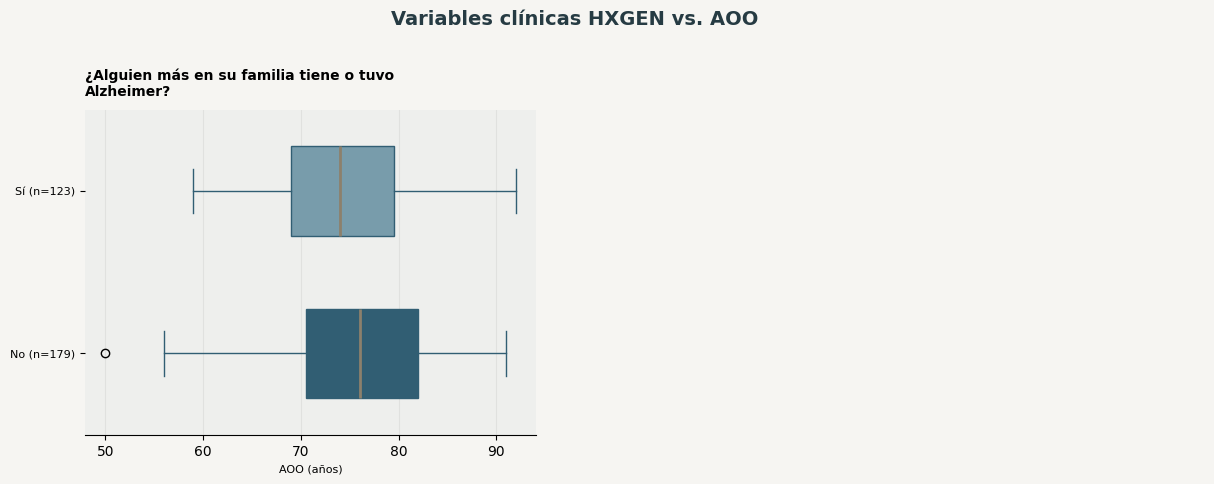

In [23]:
columnas = inventario.loc[(inventario.familia == 'historia_clinica_genetica') &
    ~inventario.tipo_analitico.isin(['identificador','variable auxiliar del EDA']), 'columna'].tolist()
display(Markdown(f"Variables integradas en la familia: **{len(columnas)}**"))

tabla_biv_hxgen = analisis_bivariado_familia(
    columnas, inventario, base_full, 'Variables clínicas HXGEN',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [24]:
mostrar_hallazgos_bivariados(tabla_biv_hxgen, 'variables clínicas HXGEN')


Se analizaron 9 variables del grupo «clínicas hxgen». 2 variables mostraron una señal estadística antes de corregir por las múltiples comparaciones. Edad presentó una tendencia marcada: sus valores más altos coincidieron con una AOO mayor; su utilidad como covariable exige confirmar la temporalidad. ¿Alguien más en su familia tiene o tuvo Alzheimer? mostró diferencias de AOO entre sus categorías (No: 76.0 años; Sí: 74.0 años); su utilidad como covariable exige confirmar la temporalidad; la interpretación de las categorías queda pendiente de validar su codificación. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. No pudieron evaluarse formalmente 14 variables, entre ellas Ciudad o municipio de residencia, Enfermedad actual, ¿Qué síntomas presenta?.

<br>

## **14. Variables neuropsicológicas por dominio vs. AOO**

Se presenta una tabla de pruebas por dominio, sin un gráfico por variable. El panel gráfico completo se reserva para MMSE, MoCA y FAST.

> **Advertencia central:** estas pruebas constituyen una exploración secundaria. Muchas mediciones neuropsicológicas son contemporáneas o posteriores al inicio y tienen riesgo de leakage «Potencial» o «Alto». Que TSCOL, TSMYD, TSPAL u otra prueba sobreviva FDR significa únicamente que su valor actual covaría con AOO dentro de esta cohorte. **No demuestra que sea un modificador de la edad de inicio, un antecedente ni un predictor válido.**

TMTA se audita de forma específica porque mezcla números con comillas, signos `+`, guiones y ceros. No se fuerza su conversión ni se interpreta una prueba categórica mientras esa codificación no esté validada.

In [25]:
# ── 22.13 Variables neuropsicológicas por dominio vs. AOO ──

cols_nps_biv = list(dict.fromkeys(
    [c for c in neuro_norm if c in base_full.columns]
    + (['moca__moca'] if 'moca__moca' in base_full.columns else [])
))
resultados_nps_biv = [
    prueba_bivariada_aoo(c, inventario, base_full, CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)
    for c in cols_nps_biv
]
tabla_nps_biv = pd.DataFrame(resultados_nps_biv)
pruebas_bivariadas_globales.extend(resultados_nps_biv)

columnas_mostrar = ['variable', 'familia', 'tipo_analitico', 'riesgo_leakage_aoo', 'evaluable', 'prueba',
                    'n', 'estadistico', 'medida_efecto', 'medida_efecto_nombre', 'direccion',
                    'medianas_por_grupo', 'codificacion_validada', 'alerta_codificacion', 'p_valor', 'motivo']
for c in columnas_mostrar:
    if c not in tabla_nps_biv.columns:
        tabla_nps_biv[c] = np.nan

nombres_biv = {
    "variable": "Variable",
    "tipo_analitico": "Tipo analítico",
    "riesgo_leakage_aoo": "Riesgo leakage AOO",
    "evaluable": "Evaluable",
    "prueba": "Prueba",
    "n": "n",
    "estadistico": "Estadístico",
    "medida_efecto": "Medida de efecto",
    "medida_efecto_nombre": "Tipo de efecto",
    "direccion": "Dirección",
    "medianas_por_grupo": "Medianas por grupo",
    "codificacion_validada": "Codificación validada",
    "alerta_codificacion": "Alerta codificación",
    "p_valor": "p valor",
    "motivo": "Motivo",
}

def dict_a_lineas(d):
    return "\n".join(f"{k}: {v}" for k, v in d.items()) if isinstance(d, dict) else ""

# Tablas por dominio
for dominio, tabla in tabla_nps_biv.groupby('familia', sort=False):
    display(Markdown('**' + dominio.replace('_', ' ').capitalize() + '**'))
    vista = tabla[columnas_mostrar].drop(columns='familia').reset_index(drop=True)
    vista["medianas_por_grupo"] = vista["medianas_por_grupo"].apply(dict_a_lineas)
    mostrar_tabla(vista, alto=400, renombrar=nombres_biv, decimales=4,
                  ajustar_texto=True, espacio=20, multilinea=["Medianas por grupo"])

display(Markdown(
    '**Nota de interpretación:** ver advertencia de leakage al inicio de esta subsección. '
    'Las correlaciones de redundancia entre pruebas neuropsicológicas ya figuran en la Sección 20.3 '
    'y no se repiten aquí.'))

# Diagnóstico de TMTA y TMTB
display(Markdown('**Diagnóstico específico de formato para TMTA y TMTB**'))
diag_tmt = pd.concat(
    [diagnostico_conversion_numerica(c, inventario, base_full, CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO)
     for c in ('neuro__tmta', 'neuro__tmtb') if c in base_full.columns],
    ignore_index=True)
diag_tmt["ejemplos_no_convertibles"] = diag_tmt["ejemplos_no_convertibles"].apply(dict_a_lineas)

mostrar_tabla(
    diag_tmt, alto=300, decimales=1, ajustar_texto=True, espacio=10,
    renombrar={
        "variable": "Variable",
        "n_no_faltante": "n no faltante",
        "convertible_directo_pct": "% convertible directo",
        "convertible_limpio_pct": "% convertible tras limpieza",
        "n_ceros": "N.º ceros",
        "ejemplos_no_convertibles": "Valores no convertibles (frecuencia)",
    },
    formato={"n no faltante": "{:.0f}", "N.º ceros": "{:.0f}"},
    multilinea=["Valores no convertibles (frecuencia)"],
)
display(Markdown('TMTA queda fuera de inferencia formal hasta validar comillas, signo `+`, guiones y ceros. '
                 'TMTB se conserva según la clasificación existente, pero también requiere confirmar el '
                 'significado de cero antes de una interpretación clínica.'))

**Metadatos nps**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo
¿Hay valoración NPS anterior?,categórica binaria,Potencial,False,—,324.0000,—,—,—,—,,True,,—,Menos de 2 categorías con n≥5
Si tiene anteriormente valoración NPS ¿en que fecha se aplico?,texto libre / alta cardinalidad,Potencial,False,—,—,—,—,—,—,,True,,—,Tipo no apto para prueba formal


**Cognicion global**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo
MMSE,cuantitativa discreta,Alto,True,Spearman,331.0000,-0.0853,-0.0853,rho de Spearman,Valores mayores asociados con AOO menor,,True,,0.1216,—
ESC DETERIOROGLOBAL,ordinal,Alto,True,Spearman,333.0000,-0.0102,-0.0102,rho de Spearman,Valores mayores asociados con AOO menor,,True,,0.8523,—
MoCA,cuantitativa discreta,Alto,True,Spearman,333.0000,-0.0199,-0.0199,rho de Spearman,Valores mayores asociados con AOO menor,,True,,0.7169,—


**Memoria**

...

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo
QUEJAS SUBJETIVAS,texto libre / alta cardinalidad,Alto,False,—,—,—,—,—,—,,True,,—,Tipo no apto para prueba formal
YESAVAGE,cuantitativa discreta,Alto,True,Spearman,320.0000,0.0203,0.0203,rho de Spearman,Valores mayores asociados con AOO mayor,,True,,0.7173,—
BARTHEL,cuantitativa discreta,Alto,True,Spearman,334.0000,-0.0520,-0.0520,rho de Spearman,Valores mayores asociados con AOO menor,,True,,0.3430,—
LAWTON Y BRODY,cuantitativa discreta,Alto,True,Spearman,334.0000,0.1419,0.1419,rho de Spearman,Valores mayores asociados con AOO mayor,,True,,0.0094,—
IKATZ,cuantitativa discreta,Alto,True,Spearman,334.0000,0.0415,0.0415,rho de Spearman,Valores mayores asociados con AOO mayor,,True,,0.4493,—
FAST,ordinal,Alto,True,Spearman,334.0000,0.0364,0.0364,rho de Spearman,Valores mayores asociados con AOO mayor,,True,,0.5077,—


**Nota de interpretación:** ver advertencia de leakage al inicio de esta subsección. Las correlaciones de redundancia entre pruebas neuropsicológicas ya figuran en la Sección 20.3 y no se repiten aquí.

**Diagnóstico específico de formato para TMTA y TMTB**

Variable,n no faltante,% convertible directo,% convertible tras limpieza,N.º ceros,Valores no convertibles (frecuencia)
TMTA,387,57.6,93.8,183,"No registrado: 24 180"": 9 240"": 4 200"": 3 70"": 3 360"": 3 116+: 2 227"": 2 108"": 2 122"": 2 85"": 2 248"": 2 69"": 2 142"": 2 119"": 2"
TMTB,306,100.0,100.0,286,


TMTA queda fuera de inferencia formal hasta validar comillas, signo `+`, guiones y ceros. TMTB se conserva según la clasificación existente, pero también requiere confirmar el significado de cero antes de una interpretación clínica.

#### **Hallazgos principales**


In [26]:
mostrar_hallazgos_bivariados(tabla_nps_biv, 'variables neuropsicológicas por dominio')

Se analizaron 53 variables del grupo «neuropsicológicas por dominio». 18 variables mostraron una señal estadística antes de corregir por las múltiples comparaciones. TSCOL presentó una tendencia débil: sus valores más altos coincidieron con una AOO menor; su utilidad como covariable exige confirmar la temporalidad. TSMYDORAL presentó una tendencia débil: sus valores más altos coincidieron con una AOO menor; su utilidad como covariable exige confirmar la temporalidad. TSMYD ESCR presentó una tendencia débil: sus valores más altos coincidieron con una AOO menor; su utilidad como covariable exige confirmar la temporalidad. TSPAL presentó una tendencia débil: sus valores más altos coincidieron con una AOO menor; su utilidad como covariable exige confirmar la temporalidad. 14 señales preliminares adicionales se detallan en la tabla. Estas señales deben contrastarse con el ajuste FDR del resumen consolidado. No pudieron evaluarse formalmente 4 variables, entre ellas ¿Hay valoración NPS anterior?, Si tiene anteriormente valoración NPS ¿en que fecha se aplico?, TMTA.

<br>

## **15. Cognición global y estado funcional (MMSE, MoCA, FAST) vs. AOO**

Panel gráfico completo (dispersión para MMSE y MoCA, cajas por estadio para FAST) para las tres variables priorizadas en la Sección 20.4. Las tres tienen riesgo de leakage «Alto»: se exploran por su relevancia clínica, no como predictores válidos de AOO.

**Pruebas de asociación con AOO — Cognición global y estado funcional: MMSE, MoCA y FAST**

Variable,Tipo analítico,Riesgo leakage AOO,Evaluable,Prueba,n,Estadístico,Medida de efecto,Tipo de efecto,Dirección,Medianas por grupo,Codificación validada,Alerta codificación,p valor,Motivo,Nota
MMSE,cuantitativa discreta,Alto,Sí,Spearman,331,-0.09,-0.085,rho de Spearman,Valores mayores asociados con AOO menor,—,Sí,—,0.1216,—,—
MoCA,cuantitativa discreta,Alto,Sí,Spearman,333,-0.02,-0.020,rho de Spearman,Valores mayores asociados con AOO menor,—,Sí,—,0.7169,—,—
FAST,ordinal,Alto,Sí,Spearman,334,0.04,0.036,rho de Spearman,Valores mayores asociados con AOO mayor,—,Sí,—,0.5077,—,—


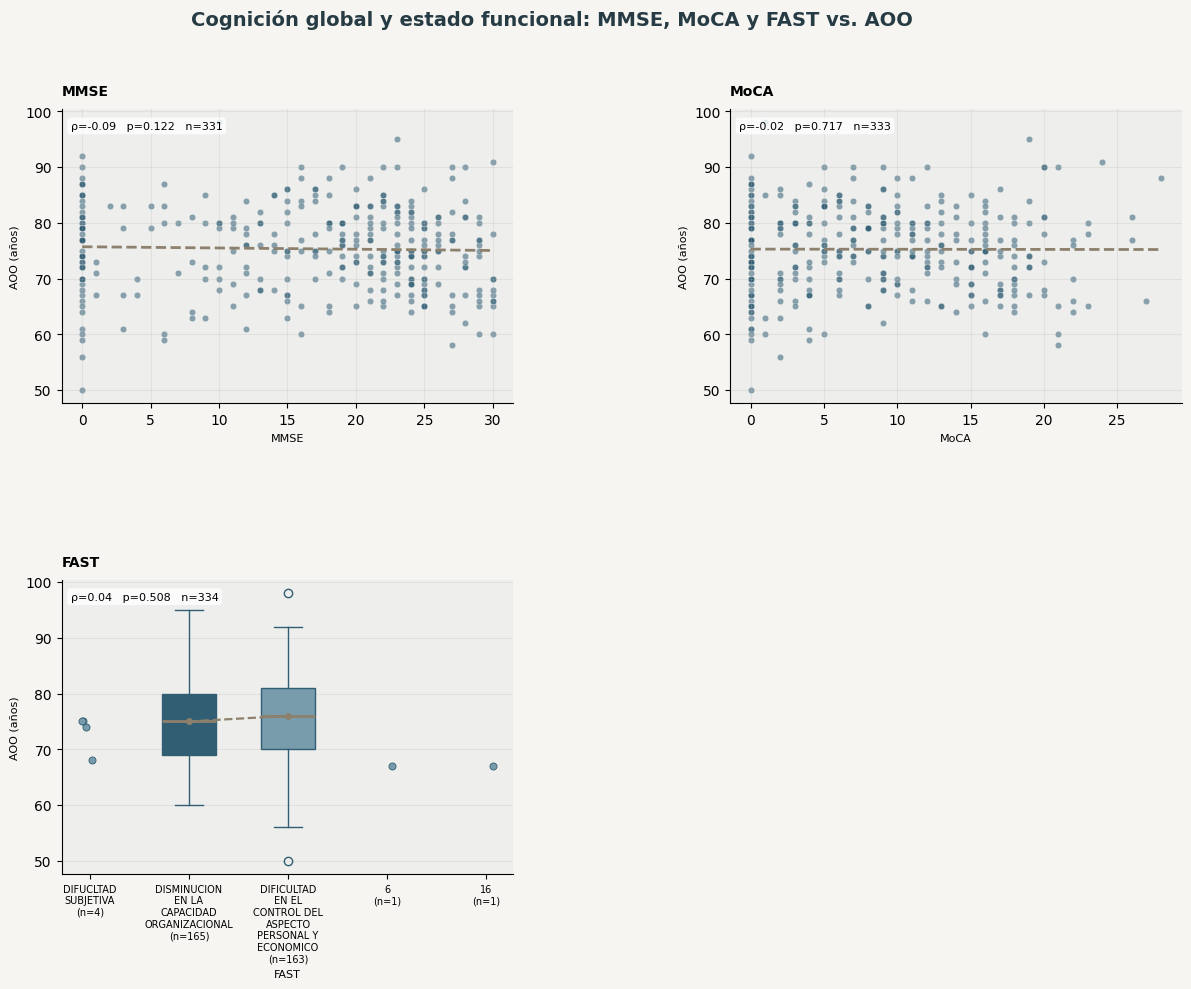

In [27]:
core_bivariado = [c for c in ('neuro__mmse', 'moca__moca', 'neuro__fast') if c in base_full.columns]

tabla_biv_core = analisis_bivariado_familia(
    core_bivariado, inventario, base_full,
    'Cognición global y estado funcional: MMSE, MoCA y FAST',
    CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO,
    acumulador=pruebas_bivariadas_globales
)

#### **Hallazgos principales**


In [28]:
mostrar_hallazgos_bivariados(tabla_biv_core, 'cognición global y estado funcional')

Se analizaron 3 variables del grupo «cognición global y estado funcional». Ninguna mostró señal con p<0.05 antes de corregir por comparaciones múltiples.

<br>

## **16. Tabla consolidada de asociaciones con AOO y corrección por comparaciones múltiples**

Se consolidan todas las pruebas acumuladas en `pruebas_bivariadas_globales` (una fila por variable única; si una variable fue probada en más de una subsección —p. ej. MMSE, MoCA o FAST, presentes tanto en 22.13 como en 22.14— se conserva un único registro). Sobre el conjunto de pruebas evaluables se aplica la corrección de Benjamini-Hochberg (FDR) para controlar la tasa de falsos descubrimientos dado el número de comparaciones realizadas.

Los resultados se presentan también segmentados por `riesgo_leakage_aoo`, para separar explícitamente las asociaciones más interpretables como posibles covariables previas al inicio (riesgo «Bajo») de aquellas que reflejan sobre todo el estado clínico actual (riesgo «Alto»/«Potencial») o que requieren validar la temporalidad («Revisar temporalidad»).

In [29]:
tabla_global_bivariado = (pd.DataFrame(pruebas_bivariadas_globales)
                          .drop_duplicates(subset='columna').reset_index(drop=True))
es_evaluable = tabla_global_bivariado['evaluable'].fillna(False).astype(bool)
evaluables = tabla_global_bivariado.loc[es_evaluable].copy()
no_evaluables = tabla_global_bivariado.loc[~es_evaluable].copy()

rechazo, p_ajustado, _, _ = multipletests(evaluables['p_valor'], method='fdr_bh', alpha=.05)
evaluables['p_ajustado_fdr'] = p_ajustado
evaluables['significativo_fdr_005'] = rechazo
evaluables = evaluables.sort_values('p_ajustado_fdr').reset_index(drop=True)

# Los IC se calculan solo para los resultados significativos tras FDR,
# evitando una carga innecesaria para todas las pruebas exploratorias.
evaluables['ic95_efecto_inf'] = np.nan
evaluables['ic95_efecto_sup'] = np.nan
for idx, fila in evaluables.loc[evaluables.significativo_fdr_005].iterrows():
    lo, hi = bootstrap_ic_efecto(
        fila.columna, fila.prueba.split(' (')[0], inventario, base_full,
        CODIGO_NO_REGISTRADO, ETIQUETA_NO_REGISTRADO, n_boot=1000
    )
    evaluables.loc[idx, ['ic95_efecto_inf', 'ic95_efecto_sup']] = [lo, hi]

display(Markdown(
    f'**Benjamini–Hochberg (FDR, α=0.05):** {len(evaluables)} pruebas evaluables; '
    f'{int((evaluables.p_valor < .05).sum())} con p crudo < 0.05 y '
    f'{int(evaluables.significativo_fdr_005.sum())} significativas tras FDR. '
    'Los IC 95% bootstrap se muestran para estas últimas.'))

columnas_mostrar_global = ['variable', 'familia', 'tipo_analitico', 'riesgo_leakage_aoo',
    'codificacion_validada', 'alerta_codificacion', 'prueba', 'n', 'estadistico', 'medida_efecto',
    'ic95_efecto_inf', 'ic95_efecto_sup', 'direccion', 'medianas_por_grupo', 'p_valor',
    'p_ajustado_fdr', 'significativo_fdr_005']
for col in columnas_mostrar_global:
    if col not in evaluables:
        evaluables[col] = np.nan

vista_global = evaluables[columnas_mostrar_global].head(10).copy()
vista_global["medianas_por_grupo"] = vista_global["medianas_por_grupo"].apply(dict_a_lineas)

mostrar_tabla(
    vista_global, alto=450, decimales=4, ajustar_texto=True, espacio=10,
    renombrar={
        **nombres_biv,
        "familia": "Familia",
        "ic95_efecto_inf": "IC 95% inf.",
        "ic95_efecto_sup": "IC 95% sup.",
        "p_ajustado_fdr": "p ajustado (FDR)",
        "significativo_fdr_005": "Significativa tras FDR",
    },
    multilinea=["Medianas por grupo"],
)

**Benjamini–Hochberg (FDR, α=0.05):** 92 pruebas evaluables; 29 con p crudo < 0.05 y 21 significativas tras FDR. Los IC 95% bootstrap se muestran para estas últimas.

Variable,Familia,Tipo analítico,Riesgo leakage AOO,Codificación validada,Alerta codificación,Prueba,n,Estadístico,Medida de efecto,IC 95% inf.,IC 95% sup.,Dirección,Medianas por grupo,p valor,p ajustado (FDR),Significativa tras FDR
EDAD,sociodemograficas,cuantitativa continua,Bajo / revisar temporalidad,True,,Spearman,334.0000,0.8403,0.8403,0.7825,0.8923,Valores mayores asociados con AOO mayor,,0.0000,0.0000,True
Edad,historia_clinica_genetica,cuantitativa continua,Revisar temporalidad,True,,Spearman,333.0000,0.8244,0.8244,0.7602,0.8751,Valores mayores asociados con AOO mayor,,0.0000,0.0000,True
TSCOL,funcion_ejecutiva_atencion,cuantitativa discreta,Potencial,True,,Spearman,311.0000,-0.2302,-0.2302,-0.3399,-0.1132,Valores mayores asociados con AOO menor,,0.0000,0.0013,True
TSMYDORAL,memoria_semantica_conocimiento,cuantitativa discreta,Potencial,True,,Spearman,309.0000,-0.2265,-0.2265,-0.3237,-0.1197,Valores mayores asociados con AOO menor,,0.0001,0.0013,True
TSMYD ESCR,memoria_semantica_conocimiento,cuantitativa discreta,Potencial,True,,Spearman,309.0000,-0.2177,-0.2177,-0.3228,-0.1092,Valores mayores asociados con AOO menor,,0.0001,0.0021,True
TSPAL,funcion_ejecutiva_atencion,cuantitativa discreta,Potencial,True,,Spearman,312.0000,-0.2027,-0.2027,-0.3058,-0.0910,Valores mayores asociados con AOO menor,,0.0003,0.0048,True
Hipertensión arterial,metabolicos_otros,categórica binaria,Revisar temporalidad,True,,U de Mann-Whitney,333.0000,10615.0000,0.2212,0.0971,0.3415,Comparar medianas de AOO entre grupos,No: 73.0 Sí: 77.0,0.0005,0.0070,True
FCROCOP,praxia_visuoconstruccion,cuantitativa discreta,Potencial,True,,Spearman,328.0000,-0.1789,-0.1789,-0.2805,-0.0715,Valores mayores asociados con AOO menor,,0.0011,0.0112,True
TSPALCOL,funcion_ejecutiva_atencion,cuantitativa discreta,Potencial,True,,Spearman,311.0000,-0.1797,-0.1797,-0.2928,-0.0668,Valores mayores asociados con AOO menor,,0.0015,0.0112,True
Tipo de residencia,sociodemograficas,categórica nominal,Bajo / revisar temporalidad,True,,U de Mann-Whitney,332.0000,7067.5000,-0.3265,0.1275,0.4927,Comparar medianas de AOO entre grupos,"Hospital, hospicio, asilo de ancianos, residencia de cuidados médicos especializados: 80.0 Residencia privada (departamento, condominio, casa): 75.0",0.0014,0.0112,True


In [30]:
resumen_fdr_tres_grupos = evaluables.loc[evaluables.significativo_fdr_005].copy()
resumen_fdr_tres_grupos['grupo_metodologico'] = resumen_fdr_tres_grupos.riesgo_leakage_aoo.map(grupo_interpretacion_fdr)
cols_resumen = ['variable', 'familia', 'riesgo_leakage_aoo', 'prueba', 'n', 'medida_efecto',
                'ic95_efecto_inf', 'ic95_efecto_sup', 'direccion', 'medianas_por_grupo',
                'p_ajustado_fdr', 'codificacion_validada', 'alerta_codificacion']

for grupo in ['1. Significativas tras FDR — riesgo Bajo',
              '2. Significativas tras FDR — requiere revisar temporalidad',
              '3. Significativas tras FDR — riesgo Potencial/Alto']:
    display(Markdown('#### ' + grupo))
    sub = resumen_fdr_tres_grupos.loc[resumen_fdr_tres_grupos.grupo_metodologico.eq(grupo), cols_resumen]
    if sub.empty:
        display(Markdown('Ninguna asociación en este grupo.'))
        continue

    sub = sub.reset_index(drop=True)
    sub["medianas_por_grupo"] = sub["medianas_por_grupo"].apply(dict_a_lineas)
    for c in ["codificacion_validada", "alerta_codificacion"]:
        es_bool = sub[c].map(type).eq(bool)
        sub[c] = sub[c].where(~es_bool, sub[c].map({True: "Sí", False: "No"}))
    sub["n"] = pd.to_numeric(sub["n"], errors="coerce").astype("Int64")

    mostrar_tabla(
        sub,
        alto=350,
        renombrar={**nombres_biv,
                   "familia": "Familia",
                   "ic95_efecto_inf": "IC 95% inf.",
                   "ic95_efecto_sup": "IC 95% sup.",
                   "p_ajustado_fdr": "p ajustado (FDR)"},
        formato={"Medida de efecto": "{:.3f}", "IC 95% inf.": "{:.3f}",
                 "IC 95% sup.": "{:.3f}", "p ajustado (FDR)": "{:.4f}"},
        ajustar_texto=True,
        una_linea=["Prueba", "n", "Medida de efecto", "IC 95% inf.",
                   "IC 95% sup.", "p ajustado (FDR)"],
        anchos={"Variable": 300, "Familia": 160, "Riesgo leakage AOO": 170,
                "Medianas por grupo": 500, "Dirección": 220},
        multilinea=["Medianas por grupo"],
        espacio=24,
    )

#### 1. Significativas tras FDR — riesgo Bajo

Variable,Familia,Riesgo leakage AOO,Prueba,n,Medida de efecto,IC 95% inf.,IC 95% sup.,Dirección,Medianas por grupo,p ajustado (FDR),Codificación validada,Alerta codificación
Nivel educativo,sociodemograficas,Bajo,Spearman,324,-0.176,-0.281,-0.069,Valores mayores asociados con AOO menor,,0.0112,Sí,


#### 2. Significativas tras FDR — requiere revisar temporalidad

Variable,Familia,Riesgo leakage AOO,Prueba,n,Medida de efecto,IC 95% inf.,IC 95% sup.,Dirección,Medianas por grupo,p ajustado (FDR),Codificación validada,Alerta codificación
EDAD,sociodemograficas,Bajo / revisar temporalidad,Spearman,334,0.840,0.783,0.892,Valores mayores asociados con AOO mayor,,0.0000,Sí,
Edad,historia_clinica_genetica,Revisar temporalidad,Spearman,333,0.824,0.760,0.875,Valores mayores asociados con AOO mayor,,0.0000,Sí,
Hipertensión arterial,metabolicos_otros,Revisar temporalidad,U de Mann-Whitney,333,0.221,0.097,0.342,Comparar medianas de AOO entre grupos,No: 73.0 Sí: 77.0,0.0070,Sí,
Tipo de residencia,sociodemograficas,Bajo / revisar temporalidad,U de Mann-Whitney,332,-0.326,0.128,0.493,Comparar medianas de AOO entre grupos,"Hospital, hospicio, asilo de ancianos, residencia de cuidados médicos especializados: 80.0 Residencia privada (departamento, condominio, casa): 75.0",0.0112,Sí,
Estado civil,sociodemograficas,Bajo / revisar temporalidad,Kruskal-Wallis (k=4),311,0.042,0.009,0.109,Comparar medianas de AOO entre grupos,Casado: 74.0 Separado: 75.0 Soltero (nunca casado o matrimonio anulado): 74.0 Viudo: 79.0,0.0112,Sí,
Estado Habitacional,sociodemograficas,Bajo / revisar temporalidad,Kruskal-Wallis (k=6),327,0.044,0.017,0.117,Comparar medianas de AOO entre grupos,"Vive con otra persona: esposo o pareja: 75.0 Vive con otra persona: familiar, amigo o compañero de cuarto: 78.0 Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo: 71.0 Vive con un grupo de personas (familiares o no) en una residencia privada: 74.0 Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos): 80.0 Vive solo: 72.0",0.0125,Sí,


#### 3. Significativas tras FDR — riesgo Potencial/Alto

Variable,Familia,Riesgo leakage AOO,Prueba,n,Medida de efecto,IC 95% inf.,IC 95% sup.,Dirección,Medianas por grupo,p ajustado (FDR),Codificación validada,Alerta codificación
TSCOL,funcion_ejecutiva_atencion,Potencial,Spearman,311,-0.230,-0.340,-0.113,Valores mayores asociados con AOO menor,,0.0013,Sí,
TSMYDORAL,memoria_semantica_conocimiento,Potencial,Spearman,309,-0.227,-0.324,-0.120,Valores mayores asociados con AOO menor,,0.0013,Sí,
TSMYD ESCR,memoria_semantica_conocimiento,Potencial,Spearman,309,-0.218,-0.323,-0.109,Valores mayores asociados con AOO menor,,0.0021,Sí,
TSPAL,funcion_ejecutiva_atencion,Potencial,Spearman,312,-0.203,-0.306,-0.091,Valores mayores asociados con AOO menor,,0.0048,Sí,
FCROCOP,praxia_visuoconstruccion,Potencial,Spearman,328,-0.179,-0.280,-0.072,Valores mayores asociados con AOO menor,,0.0112,Sí,
TSPALCOL,funcion_ejecutiva_atencion,Potencial,Spearman,311,-0.180,-0.293,-0.067,Valores mayores asociados con AOO menor,,0.0112,Sí,
CMWESCHLER,memoria,Potencial,Spearman,323,-0.163,-0.274,-0.060,Valores mayores asociados con AOO menor,,0.0214,Sí,
BENTON,memoria_semantica_conocimiento,Potencial,Spearman,312,-0.162,-0.277,-0.057,Valores mayores asociados con AOO menor,,0.0238,Sí,
TAAVREY7,memoria,Potencial,Spearman,325,-0.158,-0.256,-0.060,Valores mayores asociados con AOO menor,,0.0238,Sí,
TMTB,funcion_ejecutiva_atencion,Potencial,Spearman,257,-0.178,-0.290,-0.058,Valores mayores asociados con AOO menor,,0.0238,Sí,


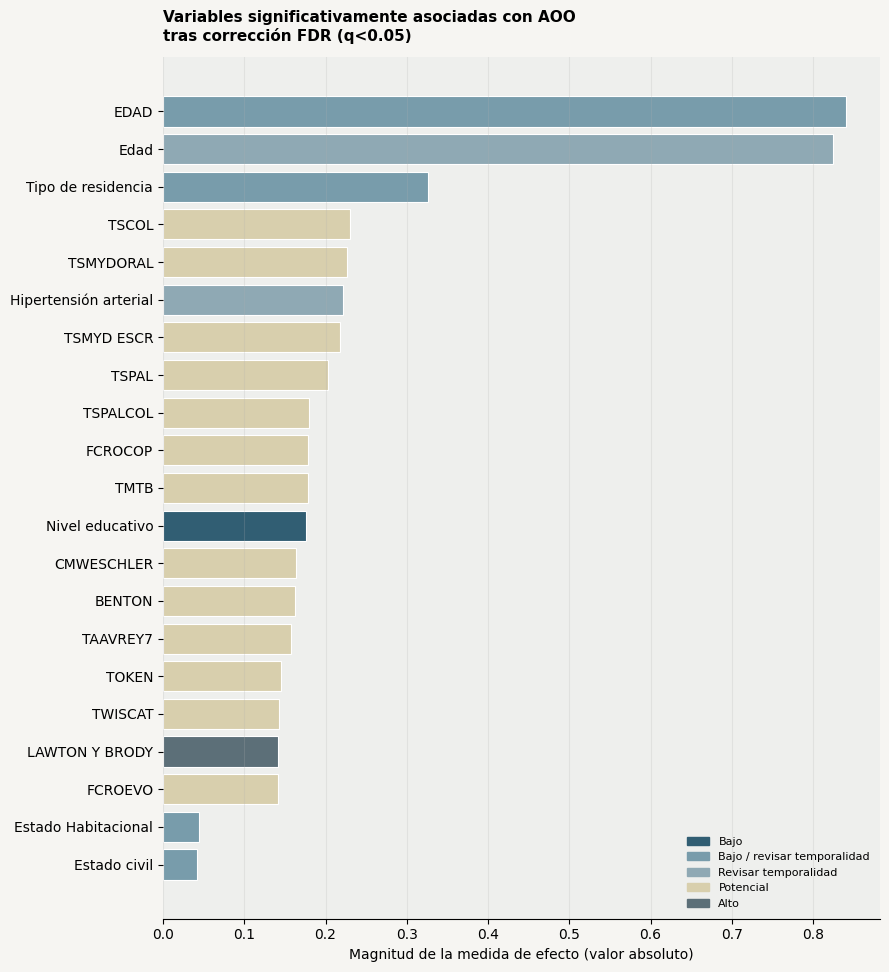

**Color por riesgo de leakage:** los tonos azules representan menor riesgo; los tonos beige/gris indican variables cuya temporalidad o interpretación requiere mayor precaución.

In [31]:
sig = evaluables.loc[evaluables.significativo_fdr_005].copy()
if sig.empty:
    display(Markdown('Ninguna variable resultó significativa tras la corrección por FDR (q<0.05).'))
else:
    sig['efecto_abs'] = sig['medida_efecto'].abs()
    sig = sig.sort_values('efecto_abs')
    sig=evaluables.loc[evaluables.significativo_fdr_005].copy()

if sig.empty:
    display(Markdown("Ninguna variable resultó significativa tras la corrección por FDR (q<0.05)."))
else:
    sig["efecto_abs"]=sig["medida_efecto"].abs()
    sig=sig.sort_values("efecto_abs")

    colores_riesgo={
        "Bajo":BC,
        "Bajo / revisar temporalidad":BC2,
        "Revisar temporalidad":"#8fa9b4",
        "Potencial":BES,
        "Alto":"#5c6f78",
        "Revisar":"#a8b7bd"
    }

    colores=[colores_riesgo.get(r,BC2) for r in sig["riesgo_leakage_aoo"]]

    fig,ax=plt.subplots(
        figsize=(9,max(3.5,.42*len(sig)+1))
    )

    fig.patch.set_facecolor(BFONDO)
    ax.set_facecolor(BPANEL)

    ax.barh(
        sig["variable"],
        sig["efecto_abs"],
        color=colores,
        edgecolor="white",
        linewidth=.8
    )

    ax.set_xlabel("Magnitud de la medida de efecto (valor absoluto)")
    ax.set_title(
        "Variables significativamente asociadas con AOO\ntras corrección FDR (q<0.05)",
        loc="left",
        fontsize=11,
        fontweight="bold",
        pad=12
    )

    ax.grid(axis="x",alpha=.22)
    ax.grid(axis="y",visible=False)
    ax.spines[["top","right","left"]].set_visible(False)

    leyenda=[
        (k,v) for k,v in colores_riesgo.items()
        if k in set(sig["riesgo_leakage_aoo"])
    ]

    handles=[
        plt.Rectangle((0,0),1,1,color=color,label=etiqueta)
        for etiqueta,color in leyenda
    ]

    if handles:
        ax.legend(
            handles=handles,
            frameon=False,
            fontsize=8,
            loc="lower right"
        )

    plt.tight_layout()
    plt.show()

    display(Markdown(
        "**Color por riesgo de leakage:** los tonos azules representan menor riesgo; "
        "los tonos beige/gris indican variables cuya temporalidad o interpretación "
        "requiere mayor precaución."
    ))


#### **Hallazgos principales**


In [32]:
hallazgos_consolidados = []
for grupo, etiqueta in [
    ('1. Significativas tras FDR — riesgo Bajo','riesgo bajo'),
    ('2. Significativas tras FDR — requiere revisar temporalidad','temporalidad pendiente'),
    ('3. Significativas tras FDR — riesgo Potencial/Alto','riesgo potencial o alto')]:
    k=int((resumen_fdr_tres_grupos.grupo_metodologico==grupo).sum())
    hallazgos_consolidados.append(f'{k} con {etiqueta}')
display(Markdown(
    f'Después de controlar las comparaciones múltiples permanecieron {int(evaluables.significativo_fdr_005.sum())} asociaciones: '
    + ', '.join(hallazgos_consolidados) + '. La mayor parte de los resultados persistentes no puede trasladarse directamente a un modelo de AOO: requiere validar temporalidad o corresponde a mediciones clínicas contemporáneas. Los intervalos de confianza muestran la precisión de los efectos destacados y deben leerse junto con estas restricciones metodológicas.'))


Después de controlar las comparaciones múltiples permanecieron 21 asociaciones: 1 con riesgo bajo, 6 con temporalidad pendiente, 14 con riesgo potencial o alto. La mayor parte de los resultados persistentes no puede trasladarse directamente a un modelo de AOO: requiere validar temporalidad o corresponde a mediciones clínicas contemporáneas. Los intervalos de confianza muestran la precisión de los efectos destacados y deben leerse junto con estas restricciones metodológicas.

<br>

## **17. Post hoc condicionado para Kruskal–Wallis**

El post hoc de Dunn se ejecuta únicamente cuando el resultado global es significativo tras FDR, la codificación está validada y la variable es interpretable. Se usa ajuste Holm dentro de cada comparación por pares. Si no se cumplen estas condiciones, no se generan comparaciones que aparenten una interpretación inexistente.

In [33]:
candidatas_dunn = evaluables.loc[
    evaluables.significativo_fdr_005.astype(bool)
    & evaluables.prueba.str.startswith('Kruskal-Wallis', na=False)
    & evaluables.codificacion_validada.fillna(False).astype(bool)
]

if candidatas_dunn.empty:
    display(Markdown('No hay variables que cumplan simultáneamente los tres criterios para ejecutar Dunn.'))
else:
    for fila in candidatas_dunn.itertuples():
        display(Markdown(f'**{fila.variable} — Dunn con ajuste Holm**'))
        mostrar_tabla(
            posthoc_dunn(fila.columna, inventario, base_full),
            alto=350, decimales=4, ajustar_texto=True, espacio=20,
            renombrar={
                "grupo_1": "Grupo 1",
                "grupo_2": "Grupo 2",
                "n_1": "n grupo 1",
                "n_2": "n grupo 2",
                "z": "z",
                "p_sin_ajuste": "p sin ajuste",
                "p_ajustado_holm": "p ajustado (Holm)",
                "significativo_005": "Significativo (p<0,05)",
            },
            formato={"n grupo 1": "{:.0f}", "n grupo 2": "{:.0f}"},
        )

**Estado civil — Dunn con ajuste Holm**

Grupo 1,Grupo 2,n grupo 1,n grupo 2,z,p sin ajuste,p ajustado (Holm),"Significativo (p<0,05)"
Casado,Separado,143,17,-0.1550,0.8768,1.0000,False
Casado,Soltero (nunca casado o matrimonio anulado),143,50,-0.2480,0.8041,1.0000,False
Casado,Viudo,143,101,-3.7913,0.0001,0.0009,True
Separado,Soltero (nunca casado o matrimonio anulado),17,50,-0.0035,0.9972,1.0000,False
Separado,Viudo,17,101,-1.7280,0.0840,0.3359,False
Soltero (nunca casado o matrimonio anulado),Viudo,50,101,-2.6141,0.0089,0.0447,True


**Estado Habitacional — Dunn con ajuste Holm**

Grupo 1,Grupo 2,n grupo 1,n grupo 2,z,p sin ajuste,p ajustado (Holm),"Significativo (p<0,05)"
Vive con otra persona: esposo o pareja,"Vive con otra persona: familiar, amigo o compañero de cuarto",87,107,-2.3763,0.0175,0.2099,False
Vive con otra persona: esposo o pareja,"Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo",87,5,0.6040,0.5458,1.0000,False
Vive con otra persona: esposo o pareja,Vive con un grupo de personas (familiares o no) en una residencia privada,87,83,-0.3471,0.7286,1.0000,False
Vive con otra persona: esposo o pareja,"Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos)",87,38,-3.4878,0.0005,0.0073,True
Vive con otra persona: esposo o pareja,Vive solo,87,7,0.8264,0.4086,1.0000,False
"Vive con otra persona: familiar, amigo o compañero de cuarto","Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo",107,5,1.3569,0.1748,1.0000,False
"Vive con otra persona: familiar, amigo o compañero de cuarto",Vive con un grupo de personas (familiares o no) en una residencia privada,107,83,1.9813,0.0476,0.4893,False
"Vive con otra persona: familiar, amigo o compañero de cuarto","Vive en una residencia de atención especializada (de asistencia de actividades de la vida diaria, residencia para adultos mayores, convento, o asilo de ancianos)",107,38,-1.7747,0.0759,0.6835,False
"Vive con otra persona: familiar, amigo o compañero de cuarto",Vive solo,107,7,1.7115,0.0870,0.6959,False
"Vive con su cuidador, quien no es su esposo/pareja, familiar o amigo",Vive con un grupo de personas (familiares o no) en una residencia privada,5,83,-0.7189,0.4722,1.0000,False


<br>

## **18. Resumen de hallazgos bivariados y pendientes**

Se caracteriza el conjunto completo de pruebas bivariadas realizadas, sin seleccionar predictores finales ni construir un modelo: esa etapa corresponde a una fase multivariada posterior (para la cual ya están importados `StandardScaler`, `PCA`, `KMeans` y `statsmodels`, aún sin usar), que además deberá incorporar las variables genéticas mencionadas en el objetivo general una vez estén disponibles y merged (Sección 23, discrepancia formal ya documentada en la Sección 3).

In [34]:
resumen_22 = pd.DataFrame([{
    'pacientes_cohorte': len(base_full),
    'AOO_disponible': int(base_full['aoo'].notna().sum()),
    'variables_evaluadas_bivariado': len(tabla_global_bivariado),
    'variables_evaluables': len(evaluables),
    'variables_no_evaluables': len(no_evaluables),
    'significativas_p_crudo_005': int((evaluables.p_valor < .05).sum()),
    'significativas_fdr_005': int(evaluables.significativo_fdr_005.sum())
}])

mostrar_tabla(
    resumen_22, alto=150, decimales=0, espacio=20,
    renombrar={
        'pacientes_cohorte': 'Pacientes en la cohorte',
        'AOO_disponible': 'Con AOO',
        'variables_evaluadas_bivariado': 'Variables revisadas',
        'variables_evaluables': 'Evaluables',
        'variables_no_evaluables': 'No evaluables',
        'significativas_p_crudo_005': 'p crudo < 0,05',
        'significativas_fdr_005': 'Significativas tras FDR',
    },
)

if no_evaluables.empty:
    display(Markdown('**Variables no evaluables:** ninguna.'))
else:
    display(Markdown('**Variables no evaluables para prueba formal, con motivo:**'))
    mostrar_tabla(
        no_evaluables[['variable', 'familia', 'tipo_analitico', 'motivo']].reset_index(drop=True),
        alto=350, ajustar_texto=True, espacio=20,
        renombrar={'variable': 'Variable', 'familia': 'Familia',
                   'tipo_analitico': 'Tipo analítico', 'motivo': 'Motivo'},
    )

assert len(base_full) == 391 and base_full['id'].is_unique


# Síntesis interpretativa reproducible de los resultados principales
n_bajo = int((resumen_fdr_tres_grupos.grupo_metodologico == '1. Significativas tras FDR — riesgo Bajo').sum())
n_temporal = int((resumen_fdr_tres_grupos.grupo_metodologico == '2. Significativas tras FDR — requiere revisar temporalidad').sum())
n_leak = int((resumen_fdr_tres_grupos.grupo_metodologico == '3. Significativas tras FDR — riesgo Potencial/Alto').sum())

# rho Edad–AOO tomado de los resultados (no escrito a mano)
fila_edad = evaluables.loc[evaluables.columna.eq('neuro__edad')]
texto_edad = (f"La correlación Edad–AOO (ρ={fila_edad.medida_efecto.iloc[0]:.2f}) se considera "
              if not fila_edad.empty else "La correlación Edad–AOO se considera ")

display(Markdown(
    f'**Lectura final:** de las {int(evaluables.significativo_fdr_005.sum())} asociaciones que sobreviven FDR, '
    f'**{n_bajo}** tienen riesgo Bajo, **{n_temporal}** requieren revisar temporalidad y '
    f'**{n_leak}** tienen riesgo Potencial/Alto. '
    + texto_edad +
    'estructuralmente esperable y no evidencia independencia como covariable. Las asociaciones con '
    'códigos no validados continúan rotuladas como preliminares, y las neuropsicológicas describen '
    'covariación contemporánea dentro de la cohorte, no modificadores demostrados de AOO.'))

Pacientes en la cohorte,Con AOO,Variables revisadas,Evaluables,No evaluables,"p crudo < 0,05",Significativas tras FDR
391,334,142,92,50,29,21


**Variables no evaluables para prueba formal, con motivo:**

Variable,Familia,Tipo analítico,Motivo
mes y año de nacimiento,sociodemograficas,texto libre / alta cardinalidad,Tipo no apto para prueba formal
IDIOMA,sociodemograficas,categórica nominal,Menos de 2 categorías con n≥5
OTRO IDOMA,sociodemograficas,texto libre / alta cardinalidad,Tipo no apto para prueba formal
Lateralidad,sociodemograficas,categórica nominal,Menos de 2 categorías con n≥5
MEDICAMENTO DEL SUJETO 1,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal
MEDICAMENTO DEL SUJETO 2,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal
MEDICAMENTO DEL SUJETO 3,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal
MEDICAMENTO DEL SUJETO 4,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal
MEDICAMENTO DEL SUJETO 5,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal
MEDICAMENTO DEL SUJETO 6,medicamentos,texto libre / alta cardinalidad,Tipo no apto para prueba formal


**Lectura final:** de las 21 asociaciones que sobreviven FDR, **1** tienen riesgo Bajo, **6** requieren revisar temporalidad y **14** tienen riesgo Potencial/Alto. La correlación Edad–AOO (ρ=0.84) se considera estructuralmente esperable y no evidencia independencia como covariable. Las asociaciones con códigos no validados continúan rotuladas como preliminares, y las neuropsicológicas describen covariación contemporánea dentro de la cohorte, no modificadores demostrados de AOO.